# Capstone 2026 Image Segmentation, Feature Extractor, and Prognosis Projection
Ryan Trask at UMBC Master's of Data Science

## Imports

In [1]:
# Standard Library & File Management
import os
import glob
import json
import gc
import re
import shutil
import warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

# Numerical & Data Science Computing
import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.ndimage import label

# Medical Imaging & Radiomics
import nibabel as nib
import SimpleITK as sitk
from radiomics import featureextractor

# Visualization
import graphviz
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Deep Learning (PyTorch & CUDA)
import torch
import torch.nn as nn

# Machine Learning (Scikit-Learn)
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import SparsePCA

# Medical Imaging Deep Learning (MONAI)
import monai
from monai.utils import set_determinism
from monai.data import Dataset, DataLoader, PersistentDataset, decollate_batch
from monai.transforms import (Compose, LoadImaged, EnsureChannelFirstd,
    Orientationd, Spacingd, NormalizeIntensityd, EnsureTyped, AsDiscrete,
    ConvertToMultiChannelBasedOnBratsClassesd, RandCropByPosNegLabeld)
from monai.networks.nets import SegResNet
from monai.losses import DiceFocalLoss
from monai.metrics import DiceMetric
from monai.inferers import sliding_window_inference

# Utilities & Jupyter Display
from tqdm.auto import tqdm
from IPython.display import display, Image, clear_output

# Configuration & Warnings Suppression
import logging
warnings.filterwarnings("ignore")
torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision('high')
torch.backends.cudnn.allow_tf32 = True

## Image Data Examination and Validation

In [2]:
# Direct path to root data folder and double-nested BraTS 2023 training directory
DATA_DIR = Path("C:/BraTS2023").resolve()
TRAIN_DIR = DATA_DIR / "ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData" / "ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData"

# Verify path existence
print(f"Data Root Directory: {DATA_DIR}")
print(f"Training Directory Exists: {TRAIN_DIR.exists()}")

# Discover all patient directories in BraTS 2023 GLI (prefix: BraTS-GLI-)
patient_dirs = [d for d in TRAIN_DIR.iterdir() if d.is_dir() and d.name.startswith("BraTS-GLI-")]
print(f"Discovered {len(patient_dirs)} patient volumes in BraTS 2023 GLI!")

# Build DataFrame mapping subject IDs to image directories
records = []
for p_dir in patient_dirs:
    sid = p_dir.name
    records.append({
        "BraTS2023ID": sid,
        "image_dir": p_dir,
        "split": "train_pool"})

df_dataset = pd.DataFrame(records)

# Check for metadata/mapping Excel file in root or training folder
mapping_excel_path = DATA_DIR / "BraTS2023_2017_GLI_Mapping.xlsx"
if mapping_excel_path.exists():
    df_map = pd.read_excel(mapping_excel_path)
    # Join on subject ID (handling potential column naming conventions in 2023 release)
    id_col = "BraTS2023ID" if "BraTS2023ID" in df_map.columns else df_map.columns[0]
    df_dataset = pd.merge(df_dataset, df_map, left_on="BraTS2023ID", right_on=id_col, how="left")
    print("Successfully merged BraTS 2023 mapping metadata!")
else:
    print("Mapping Excel file not found at root directory. Proceeding with folder discovery.")

print(f"\nSuccessfully loaded {len(df_dataset)} BraTS 2023 GLI subject records!")

Data Root Directory: C:\BraTS2023
Training Directory Exists: True
Discovered 1251 patient volumes in BraTS 2023 GLI!
Successfully merged BraTS 2023 mapping metadata!

Successfully loaded 1251 BraTS 2023 GLI subject records!


### Image Shape and Modality Check

In [3]:
# For viewing the data's file structure
def list_files(startpath):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print('{}{}/'.format(indent, os.path.basename(root)))
        subindent = ' ' * 4 * (level + 1)
        for f in files:
            print('{}{}'.format(subindent, f))
            
# list_files("C:\BraTS2023")

In [4]:
TRAIN_DIR = Path("C:/BraTS2023/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData").resolve()

def get_patient_nifti_paths(patient_id: str) -> dict:
    """
    Returns a dictionary of absolute Path objects for flair, t1, t1ce, t2, and seg NIfTI files
    using the official BraTS 2023 GLI file extension suffixes (-t2f, -t1n, -t1c, -t2w, -seg).
    """
    matching_dirs = [d for d in TRAIN_DIR.glob(f"*{patient_id}*") if d.is_dir()]
    
    paths = {}
    if matching_dirs:
        p_dir = matching_dirs[0]
        for file in p_dir.glob("*.nii*"):
            fname = file.name.lower()
            
            # Match 2023 GLI Suffixes
            if "-t2f." in fname or "t2f" in fname:
                paths["flair"] = file
            elif "-t1c." in fname or "t1c" in fname:
                paths["t1ce"] = file
            elif "-t1n." in fname or "t1n" in fname:
                paths["t1"] = file
            elif "-t2w." in fname or "t2w" in fname:
                paths["t2"] = file
            elif "-seg." in fname or "seg" in fname:
                paths["seg"] = file

    return paths

# Sanity Check on BraTS-GLI-00000-000
sample_patient = "BraTS-GLI-00000-000"
sample_paths = get_patient_nifti_paths(sample_patient)
print(f"Found Files for {sample_patient}:")
for modality in ["flair", "t1", "t1ce", "t2", "seg"]:
    file_path = sample_paths.get(modality)
    if file_path:
        print(f"  {modality.upper():<5}: {file_path.name} (Exists: {file_path.exists()})")
    else:
        print(f"  {modality.upper():<5}: Not Found")

Found Files for BraTS-GLI-00000-000:
  FLAIR: BraTS-GLI-00000-000-t2f.nii.gz (Exists: True)
  T1   : BraTS-GLI-00000-000-t1n.nii.gz (Exists: True)
  T1CE : BraTS-GLI-00000-000-t1c.nii.gz (Exists: True)
  T2   : BraTS-GLI-00000-000-t2w.nii.gz (Exists: True)
  SEG  : BraTS-GLI-00000-000-seg.nii.gz (Exists: True)


In [5]:
# Ensure modality verification checks for BraTS2023ID
def verify_dataset_files(df: pd.DataFrame):
    missing_records = []
    modalities = ["flair", "t1", "t1ce", "t2", "seg"]
    
    for idx, row in df.iterrows():
        pid = row["BraTS2023ID"]
        paths = get_patient_nifti_paths(pid)
        for m in modalities:
            if m not in paths or not paths[m].exists():
                missing_records.append((pid, m))
                
    if not missing_records:
        print(f"All files verified successfully for {len(df)} subjects!")
    else:
        print(f"Found {len(missing_records)} missing files:")
        for pid, m in missing_records[:10]:
            print(f"  Subject: {pid}, Missing Modality: {m}")

# Run verification on the unified BraTS 2023 GLI dataset pool
verify_dataset_files(df_dataset)

All files verified successfully for 1251 subjects!


In [6]:
def inspect_image_properties(sample_paths: dict):
    print("--- Volume Metadata ---")
    for mod, p in sample_paths.items():
        img = sitk.ReadImage(str(p))
        size = img.GetSize()         # (X, Y, Z)
        spacing = img.GetSpacing()   # (X, Y, Z) in mm
        origin = img.GetOrigin()
        direction = img.GetDirection()
        print(f"{mod.upper():<5} -> Shape: {size}, Spacing: {tuple(round(s, 2) for s in spacing)}")

inspect_image_properties(sample_paths)

--- Volume Metadata ---
SEG   -> Shape: (240, 240, 155), Spacing: (1.0, 1.0, 1.0)
T1CE  -> Shape: (240, 240, 155), Spacing: (1.0, 1.0, 1.0)
T1    -> Shape: (240, 240, 155), Spacing: (1.0, 1.0, 1.0)
FLAIR -> Shape: (240, 240, 155), Spacing: (1.0, 1.0, 1.0)
T2    -> Shape: (240, 240, 155), Spacing: (1.0, 1.0, 1.0)


### Visual Inspection and In-Image Corruption

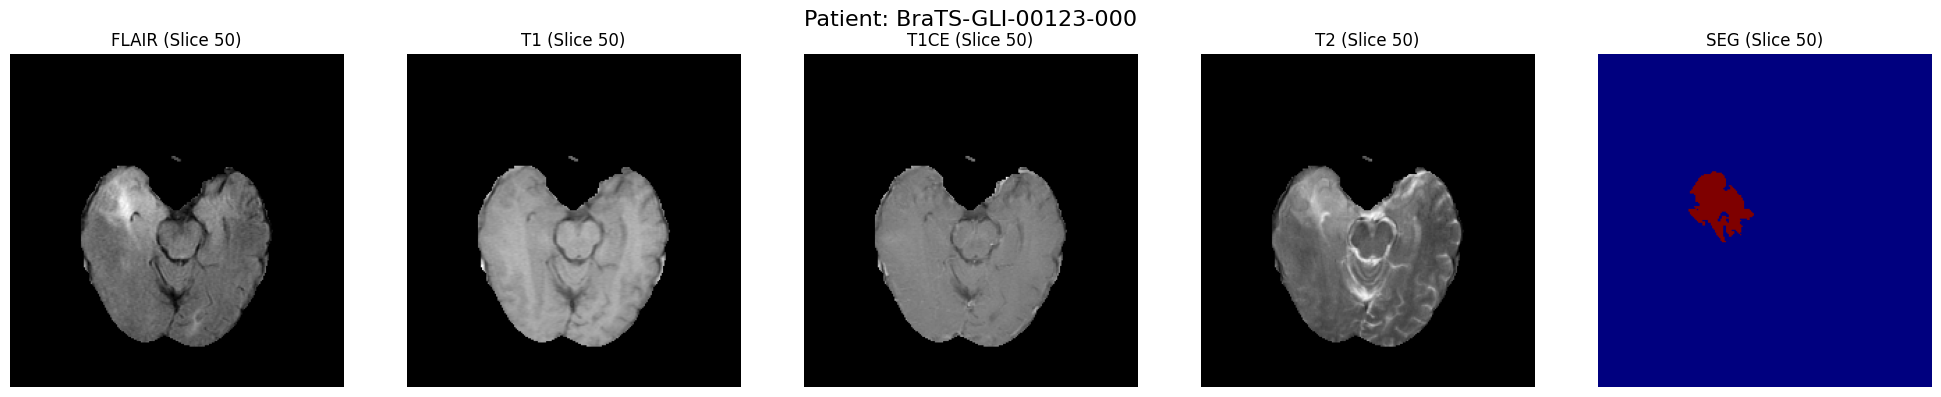

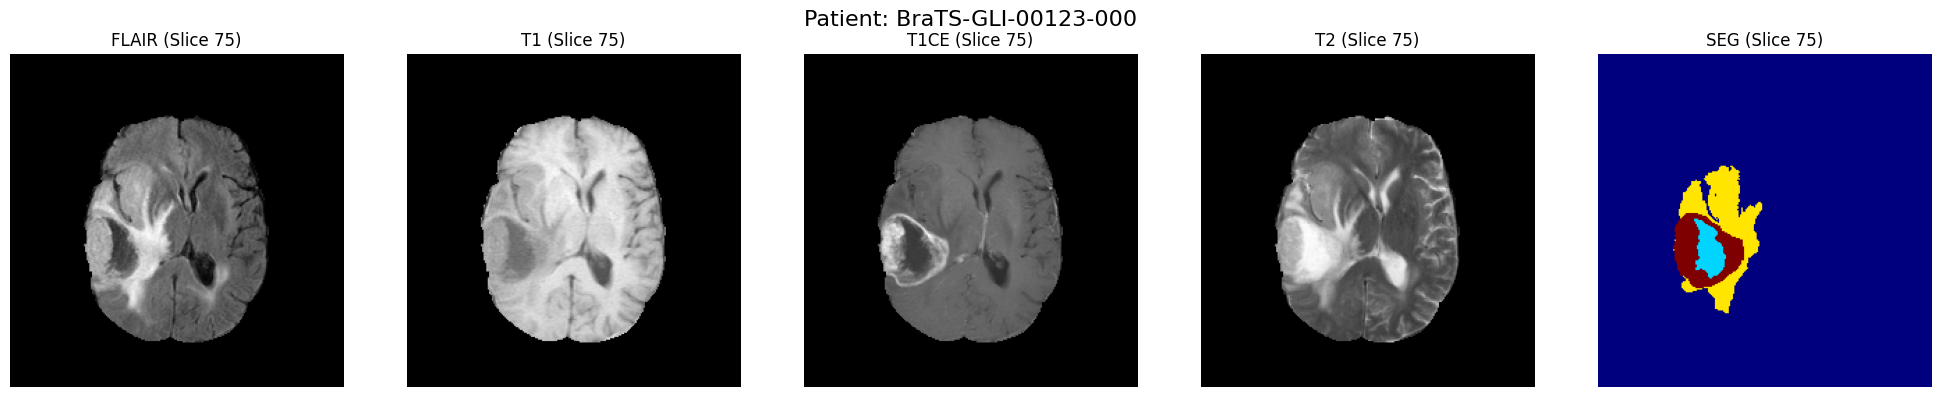

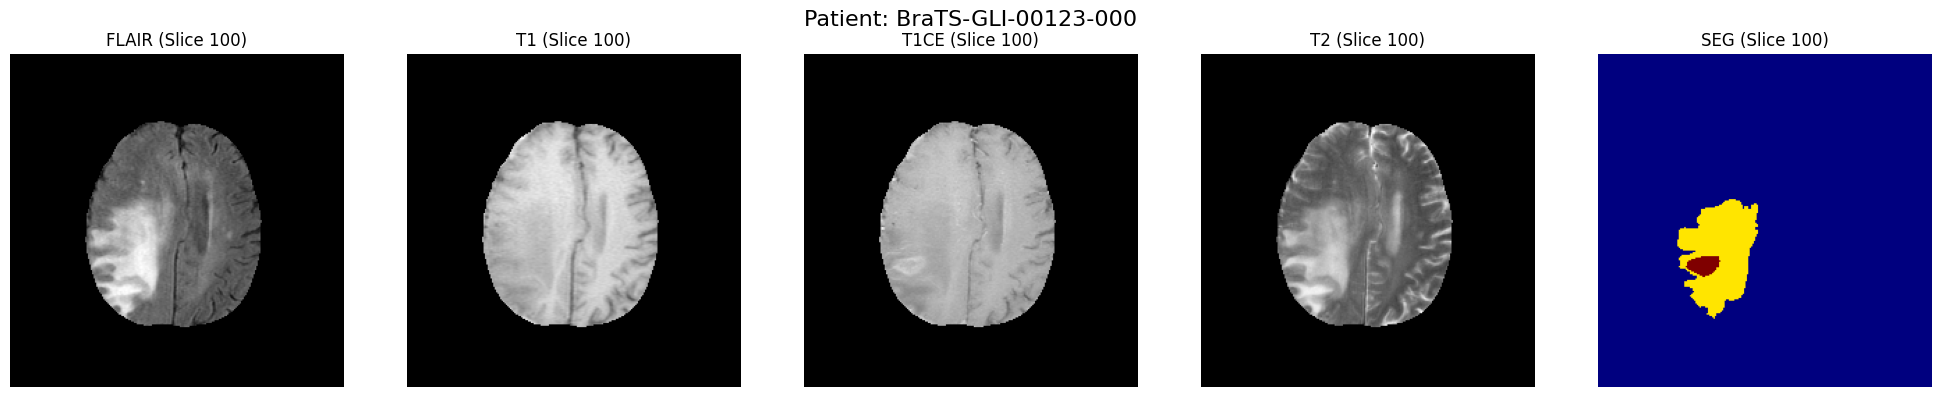

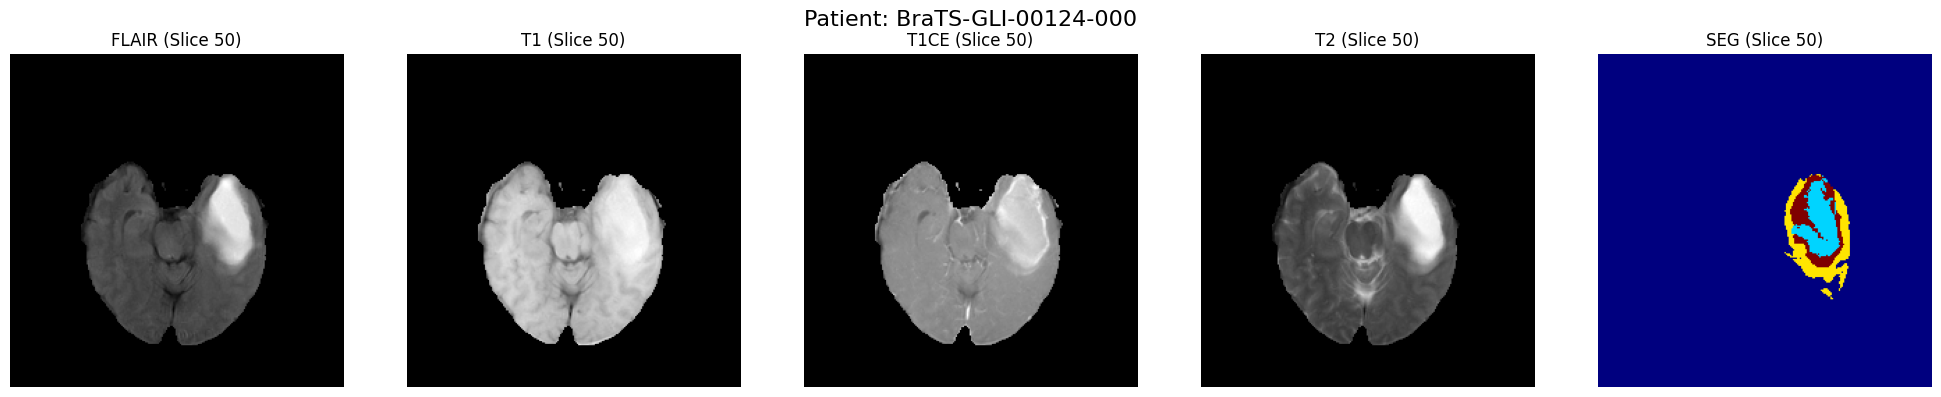

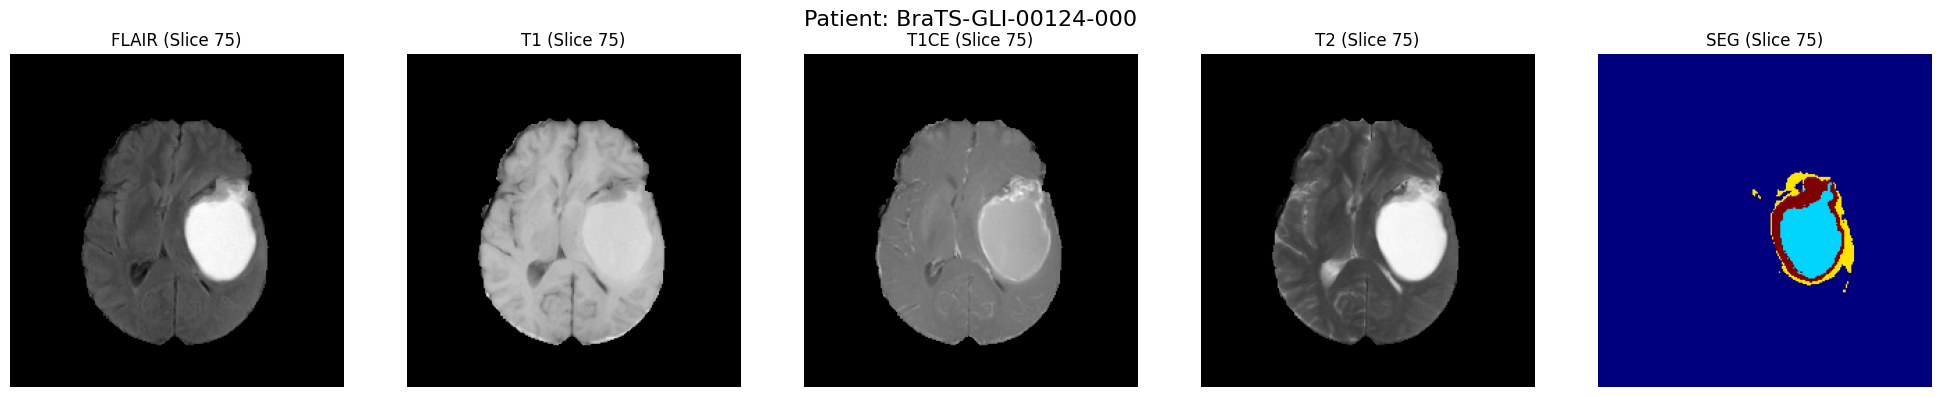

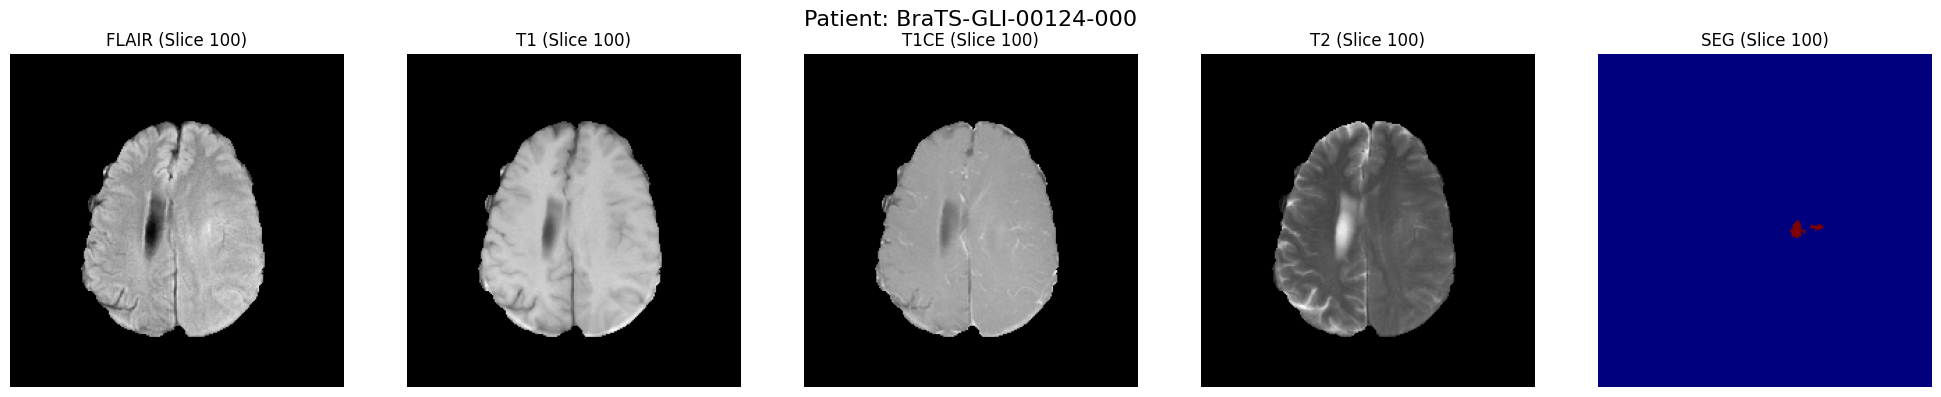

In [7]:
def plot_patient_slice(patient_id: str, slice_idx: int = 75):
    paths = get_patient_nifti_paths(patient_id)
    
    if not paths:
        print(f"No files found for patient ID: {patient_id}")
        return

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    modalities = ["flair", "t1", "t1ce", "t2", "seg"]
    
    for ax, mod in zip(axes, modalities):
        if mod in paths:
            img = sitk.GetArrayFromImage(sitk.ReadImage(str(paths[mod])))
            # SimpleITK numpy array shape is (Z, Y, X)
            ax.imshow(img[slice_idx, :, :], cmap="gray" if mod != "seg" else "jet")
            ax.set_title(f"{mod.upper()} (Slice {slice_idx})")
        else:
            ax.set_title(f"{mod.upper()} (N/A)")
        ax.axis("off")
        
    plt.suptitle(f"Patient: {patient_id}", fontsize=16)
    plt.tight_layout()
    plt.show()

# Single patient visualization updated for BraTS 2023 GLI naming convention
plot_patient_slice("BraTS-GLI-00123-000", slice_idx=50)
plot_patient_slice("BraTS-GLI-00123-000", slice_idx=75)
plot_patient_slice("BraTS-GLI-00123-000", slice_idx=100)
plot_patient_slice("BraTS-GLI-00124-000", slice_idx=50)
plot_patient_slice("BraTS-GLI-00124-000", slice_idx=75)
plot_patient_slice("BraTS-GLI-00124-000", slice_idx=100)

In [8]:
def validate_single_patient(patient_id: str) -> dict:
    """
    Validates physical metadata and voxel integrity for all 4 MRI modalities + mask.
    Runs as an independent thread.
    """
    paths = get_patient_nifti_paths(patient_id)
    
    report = {
        "BraTS2023ID": patient_id,
        "split": "train_pool",
        "is_complete": True,
        "missing_modalities": [],
        "corrupted_files": [],
        "expected_shape": (155, 240, 240), # (Z, Y, X)
        "shape_valid": True,
        "zero_signal_detected": False}
    
    required_modalities = ["flair", "t1", "t1ce", "t2", "seg"]
        
    for modality in required_modalities:
        file_path = paths.get(modality)
        
        # File Existence
        if not file_path or not file_path.exists():
            report["is_complete"] = False
            report["missing_modalities"].append(modality)
            continue
            
        # File Readability & Dimensionality via SimpleITK
        try:
            sitk_img = sitk.ReadImage(str(file_path))
            arr = sitk.GetArrayFromImage(sitk_img)
            
            if arr.shape != report["expected_shape"]:
                report["shape_valid"] = False
                
            if np.max(arr) == 0:
                report["zero_signal_detected"] = True
                
            report[f"{modality}_mean_intensity"] = float(np.mean(arr))
            report[f"{modality}_std_intensity"] = float(np.std(arr))
            
        except Exception as e:
            report["is_complete"] = False
            report["corrupted_files"].append(f"{modality}: {str(e)}")
            
    return report


def run_parallel_qa(df_dataset: pd.DataFrame, max_workers: int = 10) -> pd.DataFrame:
    """
    Executes patient image validation in parallel across multiple CPU workers.
    """
    tasks = []
    
    # Queue Task for each BraTS 2023 GLI subject
    for pid in df_dataset["BraTS2023ID"]:
        tasks.append(pid)
        
    results = []
    print(f"Starting parallel QA for {len(tasks)} total cases across {max_workers} threads...")
    
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        # Submit all tasks
        future_to_patient = {
            executor.submit(validate_single_patient, pid): pid 
            for pid in tasks}
        
        # Track progress with tqdm progress bar
        for future in tqdm(as_completed(future_to_patient), total=len(tasks), desc="Auditing NIfTI Scans"):
            patient_id = future_to_patient[future]
            try:
                data = future.result()
                results.append(data)
            except Exception as exc:
                print(f"Patient {patient_id} generated an exception: {exc}")
                
    return pd.DataFrame(results)

# Parallel Quality Audit Utilizing 8 worker threads
df_qa_all = run_parallel_qa(df_dataset, max_workers=8)

# Print Summary Statistics
print("\n=== BraTS 2023 GLI QA Audit Summary ===")
print(f"  Total Audited Cases : {len(df_qa_all)}")
print(f"  100% Complete Volumes : {df_qa_all['is_complete'].sum()} / {len(df_qa_all)}")
print(f"  Correct Shape (155x240x240): {df_qa_all['shape_valid'].sum()} / {len(df_qa_all)}")
print(f"  Corrupted/Zero Signal Scans: {df_qa_all['zero_signal_detected'].sum()}")

Starting parallel QA for 1251 total cases across 8 threads...


Auditing NIfTI Scans:   0%|          | 0/1251 [00:00<?, ?it/s]


=== BraTS 2023 GLI QA Audit Summary ===
  Total Audited Cases : 1251
  100% Complete Volumes : 1251 / 1251
  Correct Shape (155x240x240): 1251 / 1251
  Corrupted/Zero Signal Scans: 0


## Clinical Data EDA and Preprocessing for Modeling

Total uniquely mapped BraTS cases (after deduplication): 186
Saved matched records to: models_stage1\brats_matched_clinical_cases.csv

Breakdown of uniquely mapped cases by Study ID:
Study ID
gbm_tcga_pan_can_atlas_2018    98
lgg_tcga_pan_can_atlas_2018    65
gbm_cptac_2021                 19
lgggbm_tcga_pub                 4
Name: count, dtype: int64


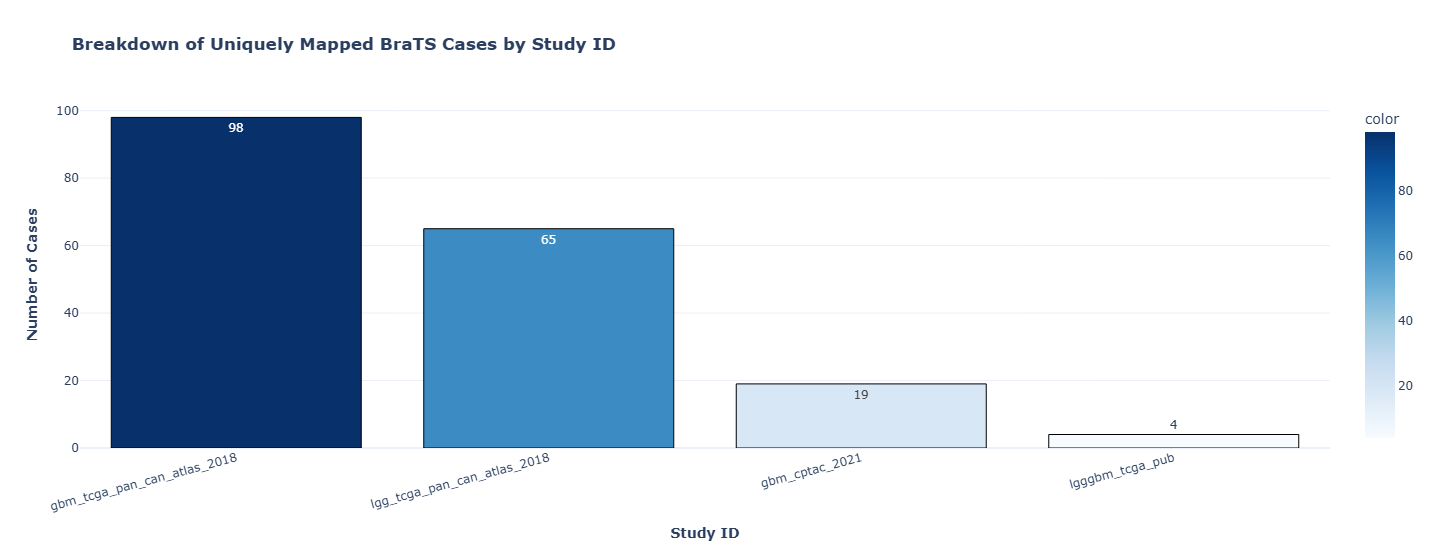

In [9]:
# Setup Directories & Load Data
DATA_DIR = Path("C:/BraTS2023").resolve()
output_dir = Path("./models_stage1")
output_dir.mkdir(parents=True, exist_ok=True)

df_map = pd.read_excel(DATA_DIR / "BraTS2023_2017_GLI_Mapping.xlsx")
df_clin = pd.read_csv(DATA_DIR / "combined_study_clinical_data.tsv", sep="\t", low_memory=False)

# Clean Identifiers (handling trailing spaces or NaN values safely)
df_map["Local ID Clean"] = df_map["Local ID "].astype(str).str.strip()
df_clin["Patient ID Clean"] = df_clin["Patient ID"].astype(str).str.strip()

# Define Study Preference Hierarchy (Lower number = higher priority)
study_priority = {
    "lgg_tcga_pan_can_atlas_2018": 1,
    "gbm_tcga_pan_can_atlas_2018": 1,
    "gbm_cptac_2021": 2,
    "lgggbm_tcga_pub": 3,
    "gbm_tcga": 4,
    "lgg_tcga": 4,
    "gbm_tcga_pub2013": 5,
    "difg_glass": 6,
    "difg_glass_2019": 6}

# Map Priority and Deduplicate Clinical Records
df_clin["Priority"] = df_clin["Study ID"].map(study_priority).fillna(99)
df_clin_dedup = df_clin.sort_values("Priority").drop_duplicates(subset=["Patient ID Clean"], keep="first")

# Merge Mapping with Deduplicated Clinical Records
matched_cases = pd.merge(
    df_map, 
    df_clin_dedup, 
    left_on="Local ID Clean", 
    right_on="Patient ID Clean", 
    how="inner")

# Export matched mapping table for downstream pipeline tracking
matched_output_path = output_dir / "brats_matched_clinical_cases.csv"
matched_cases.to_csv(matched_output_path, index=False)

# Print Summary Statistics
print(f"Total uniquely mapped BraTS cases (after deduplication): {len(matched_cases)}")
print(f"Saved matched records to: {matched_output_path}")
print("\nBreakdown of uniquely mapped cases by Study ID:")
study_counts = matched_cases["Study ID"].value_counts(dropna=False)
print(study_counts)

# Generate Plotly Bar Chart
fig = px.bar(
    x=study_counts.index,
    y=study_counts.values,
    text=study_counts.values,
    title="<b>Breakdown of Uniquely Mapped BraTS Cases by Study ID</b>",
    labels={"x": "Study ID", "y": "Case Count"},
    color=study_counts.values,
    color_continuous_scale="Blues")

fig.update_traces(textposition='auto', marker_line_color='black', marker_line_width=1)
fig.update_layout(
    template="plotly_white",
    xaxis_title="<b>Study ID</b>",
    yaxis_title="<b>Number of Cases</b>",
    xaxis_tickangle=-15,
    font=dict(size=12),
    height=550,
    width=900,
    showlegend=False)

# Display in Jupyter and save HTML copy
fig.show()
fig.write_html(output_dir / "brats_study_breakdown_bar_chart.html")

Merged Cohort of LGG and GBM (TCGA, Cell 2016)
Low-Grade Gliomas (UCSF, Science 2014)
IDH-mutated Diffuse Glioma (MSK, Clin Cancer Res 2024)
Glioma (MSK, Nature 2019)
Glioma (MSK, Clin Cancer Res 2019)
Glioblastoma Multiforme (TCGA, Firehose Legacy)
Glioblastoma (Columbia, Nat Med. 2019)
Glioblastoma (CPTAC, Cell 2021)
Diffuse Glioma (GLASS Consortium, Nature 2019)
Diffuse Glioma (GLASS Consortium)
Brain Tumor PDXs (Mayo Clinic, Clin Cancer Res 2020)
Anaplastic Oligodendroglioma and Anaplastic Oligoastrocytoma (MSK, Neuro Oncol 2017)
Glioblastoma (TCGA, Cell 2013)
Glioblastoma (TCGA, Nature 2008)
Glioblastoma Multiforme (TCGA, PanCancer Atlas)
Brain Lower Grade Glioma (TCGA, PanCancer Atlas)
Brain Lower Grade Glioma (TCGA, Firehose Legacy)


             EXPLORATORY DATA ANALYSIS (EDA) REPORT
Total Merged Cohort Size         : 1255
Matched Clinical Test Cohort Size : 166
Unannotated Segmentation Pool     : 1089
----------------------------------------------------------------------
PRE-IMPUTATION CLINICAL MISSINGNESS (166 Test Cohort):
    • Sex (Binary)                : 62/166 missing (37.3%)
    • Age at Diagnosis            : 62/166 missing (37.3%)
    • Fraction Genome Altered     : 6/166 missing (3.6%)

COMPREHENSIVE NUMERICAL VARIABLE DESCRIPTIVE STATISTICS:
              Age  Fraction_Genome_Altered  Survival_days  Progression_days   OS_Months  PFS_Months
count  104.000000               160.000000     166.000000        163.000000  166.000000  163.000000
mean    49.500000                 0.167705     733.230301        493.501717   24.087723   16.212277
std     15.528864                 0.113909     734.427492        524.004222   24.127053   17.214331
min     20.000000                 0.000000       3.002268          

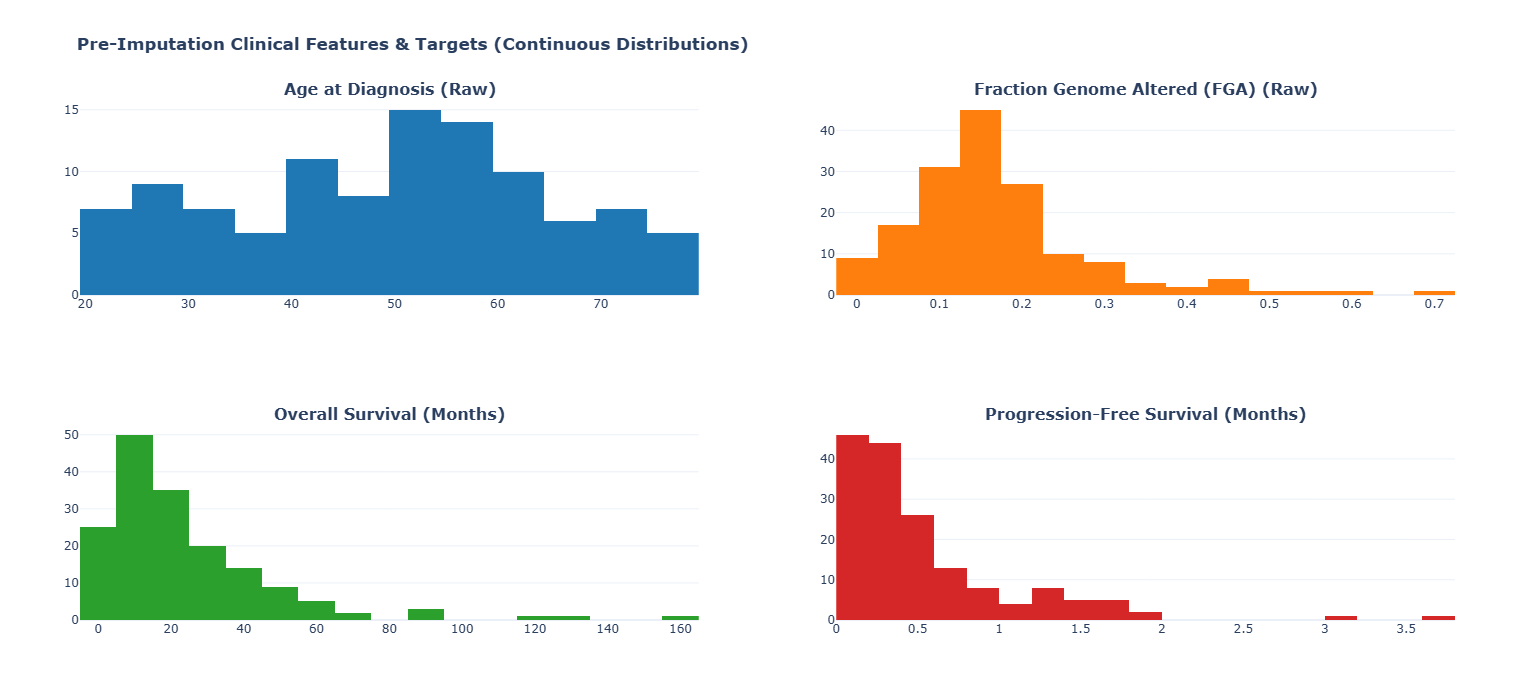

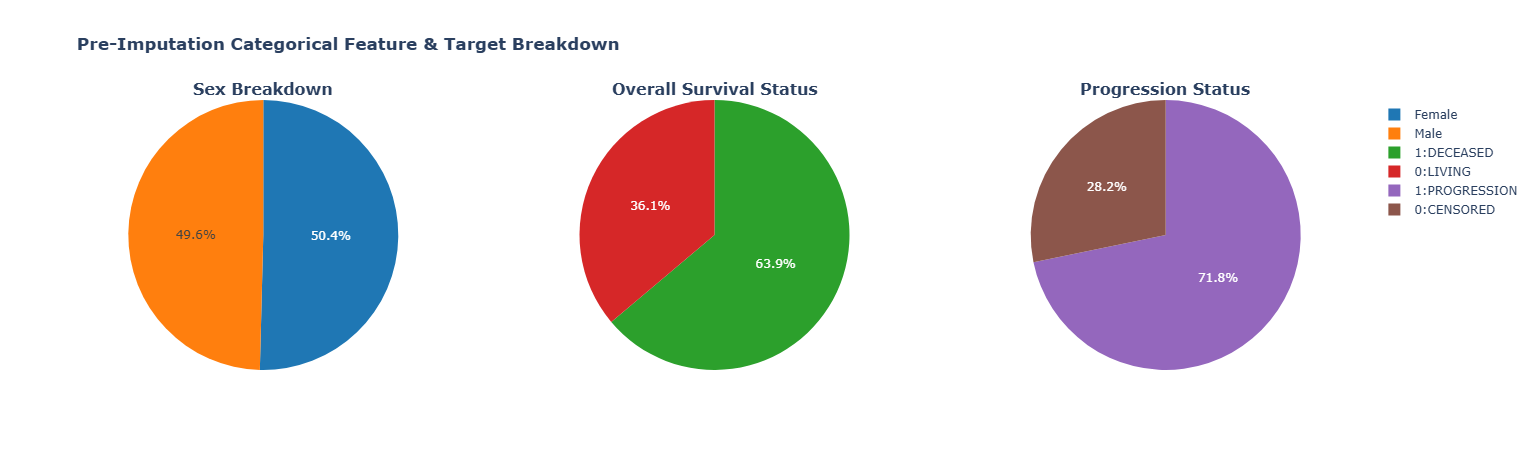


STUDY ID DISTRIBUTION BREAKDOWN:
    • Study ID 'gbm_tcga_pan_can_atlas_2018' : 98 cases[cite: 1, 2, 3]
    • Study ID 'lgg_tcga_pan_can_atlas_2018' : 65 cases[cite: 1, 2, 3]
    • Study ID 'gbm_cptac_2021' : 19 cases[cite: 1, 2, 3]
    • Study ID 'lgggbm_tcga_pub' : 4 cases[cite: 1, 2, 3]


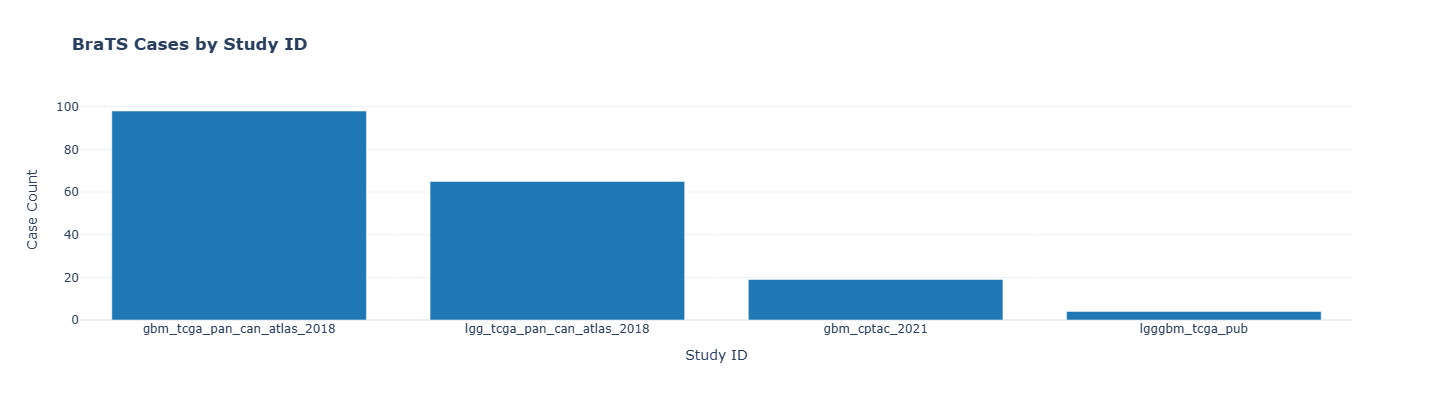


STRATIFIED RISK TIER DISTRIBUTION:
    • Risk Tier 'Long  '         : 77 patients (46.4%)
    • Risk Tier 'Short '         : 46 patients (27.7%)
    • Risk Tier 'Medium'         : 43 patients (25.9%)

            DATASET EXPORT SUMMARY
 • Held-Out Test Set (166 Cohort) : 166 cases -> models_stage1\brats_ablation_test_set_166.csv
 • Unified 5-Fold CV Pool (2-Col) : 1089 cases -> models_stage1\brats_cv_pool_5fold.csv



In [10]:
# Load Dataset, Mapping & Clinical TSV
DATA_DIR = Path("C:/BraTS2023").resolve()
IMAGE_DATA_DIR = DATA_DIR / "ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData" / "ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData"

mapping_path = DATA_DIR / "BraTS2023_2017_GLI_Mapping.xlsx"
clinical_tsv_path = DATA_DIR / "combined_study_clinical_data.tsv"

if not mapping_path.exists():
    mapping_path = Path("BraTS2023_2017_GLI_Mapping.xlsx")

df_map = pd.read_excel(mapping_path)
df_clin = pd.read_csv(clinical_tsv_path, sep="\t", low_memory=False)

cohort_col = "Cohort Name (if publicly available)"

# Clean identifiers with flexible stripping
df_map["Local ID Clean"] = df_map["Local ID "].apply(lambda x: str(x).strip().upper() if pd.notna(x) else np.nan)
df_clin["Patient ID Clean"] = df_clin["Patient ID"].apply(lambda x: str(x).strip().upper() if pd.notna(x) else np.nan)

# Deduplicate Clinical Data Across Studies
study_priority = {
    "lgg_tcga_pan_can_atlas_2018": 1,
    "gbm_tcga_pan_can_atlas_2018": 1,
    "gbm_cptac_2021": 2,
    "lgggbm_tcga_pub": 3,
    "gbm_tcga": 4,
    "lgg_tcga": 4,
    "gbm_tcga_pub2013": 5,
    "difg_glass": 6,
    "difg_glass_2019": 6}

df_clin["Priority"] = df_clin["Study ID"].map(study_priority).fillna(99)
df_clin = df_clin.sort_values("Priority").drop_duplicates(subset=["Patient ID Clean"], keep="first")

# Merge Cleaned Dataset for Pipeline
df_dataset = pd.DataFrame({
    "BraTS2023ID": df_map["BraTS2023"],
    "Cohort_Name": df_map[cohort_col].fillna("Private Collection"),
    "Local ID Clean": df_map["Local ID Clean"],
    "image_dir": df_map["BraTS2023"].apply(lambda x: str(IMAGE_DATA_DIR / str(x)))})

df_dataset = pd.merge(
    df_dataset,
    df_clin,
    left_on="Local ID Clean",
    right_on="Patient ID Clean",
    how="left")

# Polymorphic Feature & Target Extraction
df_all = df_dataset.copy()

def get_first_valid_col(df, candidates):
    for col in candidates:
        if col in df.columns and df[col].notna().sum() > 0:
            return col
    return None

age_col = get_first_valid_col(df_all, ["Diagnosis Age", "Age", "AGE"])
sex_col = get_first_valid_col(df_all, ["Sex", "GENDER", "Gender"])
fga_col = get_first_valid_col(df_all, ["Fraction Genome Altered", "FRACTION_GENOME_ALTERED", "FGA"])
survival_col = get_first_valid_col(df_all, ["Overall Survival (Months)", "OS_MONTHS", "Survival (months)"])
status_col = get_first_valid_col(df_all, ["Overall Survival Status", "OS_STATUS", "Survival Status"])
prog_days_col = get_first_valid_col(df_all, ["Progress Free Survival (Months)", "PFS_MONTHS"])
prog_status_col = get_first_valid_col(df_all, ["Progression Free Status", "PROGRESSION_STATUS", "PFS_STATUS"])

df_all["Age"] = pd.to_numeric(df_all[age_col], errors="coerce") if age_col else np.nan
df_all["Fraction_Genome_Altered"] = pd.to_numeric(df_all[fga_col], errors="coerce") if fga_col else np.nan

raw_sex = df_all[sex_col] if sex_col else pd.Series(np.nan, index=df_all.index)
def parse_sex(val):
    if pd.isna(val):
        return np.nan
    v = str(val).strip().lower()
    if v in ["male", "m", "0"]:
        return 0.0
    elif v in ["female", "f", "1"]:
        return 1.0
    return np.nan

df_all["Sex_Binary"] = raw_sex.apply(parse_sex)

df_all["Survival_days"] = pd.to_numeric(df_all[survival_col], errors="coerce") * 30.44 if survival_col else np.nan
df_all["Progression_days"] = pd.to_numeric(df_all[prog_days_col], errors="coerce") * 30.44 if prog_days_col else np.nan

def parse_status(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).lower()
    if any(k in val_str for k in ["1", "dead", "deceased", "death", "progress", "recur", "relapse"]):
        return 1.0
    elif any(k in val_str for k in ["0", "live", "living", "stable", "no progression"]):
        return 0.0
    try:
        return float(val)
    except ValueError:
        return np.nan

df_all["Survival_Status"] = df_all[status_col].apply(parse_status) if status_col else np.nan
df_all["Progression_Status"] = df_all[prog_status_col].apply(parse_status) if prog_status_col else np.nan

mask_censored = df_all["Survival_days"].notna() & df_all["Survival_Status"].isna()
df_all.loc[mask_censored, "Survival_Status"] = 0.0

# Cohort Separation & Full EDA Logging
mask_clinical_matched = df_all["Survival_days"].notna()

df_test_166 = df_all[mask_clinical_matched].copy().reset_index(drop=True)
df_unannotated = df_all[~mask_clinical_matched].copy().reset_index(drop=True)

# EDA and Audit Report with pandas describe() statistics
print("\n" + "=" * 70)
print("             EXPLORATORY DATA ANALYSIS (EDA) REPORT")
print("=" * 70)
print(f"Total Merged Cohort Size         : {len(df_all)}")
print(f"Matched Clinical Test Cohort Size : {len(df_test_166)}")
print(f"Unannotated Segmentation Pool     : {len(df_unannotated)}")
print("-" * 70)

# Pre-Imputation Missingness Audit
missing_sex = df_test_166["Sex_Binary"].isna().sum()
missing_age = df_test_166["Age"].isna().sum()
missing_fga = df_test_166["Fraction_Genome_Altered"].isna().sum()

print("PRE-IMPUTATION CLINICAL MISSINGNESS (166 Test Cohort):")
print(f"    • Sex (Binary)                : {missing_sex}/{len(df_test_166)} missing ({missing_sex/len(df_test_166):.1%})")
print(f"    • Age at Diagnosis            : {missing_age}/{len(df_test_166)} missing ({missing_age/len(df_test_166):.1%})")
print(f"    • Fraction Genome Altered     : {missing_fga}/{len(df_test_166)} missing ({missing_fga/len(df_test_166):.1%})")

# Comprehensive Pandas Describe Statistics for Relevant Numerical Variables
numeric_vars_df = df_test_166[["Age", "Fraction_Genome_Altered", "Survival_days", "Progression_days"]].copy()
numeric_vars_df["OS_Months"] = pd.to_numeric(df_test_166[survival_col], errors="coerce") if survival_col else np.nan
numeric_vars_df["PFS_Months"] = pd.to_numeric(df_test_166[prog_days_col], errors="coerce") if prog_days_col else np.nan

print("\nCOMPREHENSIVE NUMERICAL VARIABLE DESCRIPTIVE STATISTICS:")
print(numeric_vars_df.describe().to_string())
print("-" * 70)

# PRE-IMPUTATION PLOTLY VISUALIZATIONS
OUTPUT_DIR = Path("./models_stage1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Continuous Features & Targets Distribution
fig_continuous = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "<b>Age at Diagnosis (Raw)</b>",
        "<b>Fraction Genome Altered (FGA) (Raw)</b>",
        "<b>Overall Survival (Months)</b>",
        "<b>Progression-Free Survival (Months)</b>"))

fig_continuous.add_trace(
    go.Histogram(x=df_test_166["Age"].dropna(), name="Age", marker_color="#1f77b4", nbinsx=20),
    row=1, col=1)
fig_continuous.add_trace(
    go.Histogram(x=df_test_166["Fraction_Genome_Altered"].dropna(), name="FGA", marker_color="#ff7f0e", nbinsx=20),
    row=1, col=2)

os_months_raw = pd.to_numeric(df_test_166[survival_col], errors="coerce") if survival_col else pd.Series(dtype=float)
fig_continuous.add_trace(
    go.Histogram(x=os_months_raw.dropna(), name="OS (Months)", marker_color="#2ca02c", nbinsx=20),
    row=2, col=1)

pfs_months_raw = pd.to_numeric(df_test_166[prog_days_col], errors="coerce") / 30.44 if prog_days_col else pd.Series(dtype=float)
fig_continuous.add_trace(
    go.Histogram(x=pfs_months_raw.dropna(), name="PFS (Months)", marker_color="#d62728", nbinsx=20),
    row=2, col=2)

fig_continuous.update_layout(
    template="plotly_white",
    title_text="<b>Pre-Imputation Clinical Features & Targets (Continuous Distributions)</b>",
    showlegend=False,
    height=700,
    width=1100)
fig_continuous.show()
fig_continuous.write_html(OUTPUT_DIR / "pre_imputation_continuous_distributions.html")


# Categorical Features & Status Breakdown (Pre-Imputation)
fig_categorical = make_subplots(
    rows=1, cols=3,
    specs=[[{"type": "domain"}, {"type": "domain"}, {"type": "domain"}]] ,
    subplot_titles=("<b>Sex Breakdown</b>", "<b>Overall Survival Status</b>", "<b>Progression Status</b>"))

sex_counts = raw_sex.value_counts(dropna=True)
fig_categorical.add_trace(
    go.Pie(labels=sex_counts.index, values=sex_counts.values, name="Sex", marker_colors=["#1f77b4", "#ff7f0e"]),
    row=1, col=1)

surv_status_raw = df_test_166[status_col].value_counts(dropna=True) if status_col else pd.Series(dtype=int)
fig_categorical.add_trace(
    go.Pie(labels=surv_status_raw.index, values=surv_status_raw.values, name="Survival Status", marker_colors=["#2ca02c", "#d62728"]),
    row=1, col=2)

prog_status_raw = df_test_166[prog_status_col].value_counts(dropna=True) if prog_status_col else pd.Series(dtype=int)
if not prog_status_raw.empty:
    fig_categorical.add_trace(
        go.Pie(labels=prog_status_raw.index, values=prog_status_raw.values, name="Progression Status", marker_colors=["#9467bd", "#8c564b"]),
        row=1, col=3)

fig_categorical.update_layout(
    template="plotly_white",
    title_text="<b>Pre-Imputation Categorical Feature & Target Breakdown</b>",
    height=450,
    width=1100)
fig_categorical.show()
fig_categorical.write_html(OUTPUT_DIR / "pre_imputation_categorical_breakdown.html")


# Study ID Distribution Plotly Visualization (Tracking Study Cohorts)
study_counts = df_dataset["Study ID"].value_counts().reset_index()
study_counts.columns = ["Study ID", "Count"]

print("\nSTUDY ID DISTRIBUTION BREAKDOWN:")
for _, row_item in study_counts.iterrows():
    print(f"    • Study ID '{row_item['Study ID']}' : {row_item['Count']} cases[cite: 1, 2, 3]")

fig_study = go.Figure(go.Bar(
    x=study_counts["Study ID"],
    y=study_counts["Count"],
    marker_color="#1f77b4"
))
fig_study.update_layout(
    title="<b>BraTS Cases by Study ID</b>",
    xaxis_title="Study ID",
    yaxis_title="Case Count",
    template="plotly_white",
    height=400,
    width=800
)
fig_study.show()
fig_study.write_html(OUTPUT_DIR / "brats_cases_by_study_id.html")


# IMPUTATION & RISK TIERS
df_test_166["Sex_Binary"] = df_test_166["Sex_Binary"].fillna(0.5)
df_test_166["Age"] = df_test_166["Age"].fillna(df_test_166["Age"].median())
df_test_166["Fraction_Genome_Altered"] = df_test_166["Fraction_Genome_Altered"].fillna(df_test_166["Fraction_Genome_Altered"].median())

def assign_survival_tier(days):
    if pd.isna(days):
        return np.nan
    if days < 300:
        return "Short"
    elif days <= 550:
        return "Medium"
    else:
        return "Long"

df_test_166["Survival_Risk_Tier"] = df_test_166["Survival_days"].apply(assign_survival_tier)

tier_counts = df_test_166["Survival_Risk_Tier"].value_counts()
print("\nSTRATIFIED RISK TIER DISTRIBUTION:")
for tier, count in tier_counts.items():
    print(f"    • Risk Tier '{tier:<6}'         : {count} patients ({count/len(df_test_166):.1%})")
print("=" * 70 + "\n")

# Scale clinical features for test export
num_features = ["Age", "Fraction_Genome_Altered", "Sex_Binary"]
scaler = StandardScaler()
X_test_processed = scaler.fit_transform(df_test_166[num_features])
encoded_cols = scaler.get_feature_names_out(num_features)
df_test_features = pd.DataFrame(X_test_processed, columns=encoded_cols)

df_test_preprocessed = pd.DataFrame({
    "BraTS2023ID": df_test_166["BraTS2023ID"],
    "Cohort_Name": df_test_166["Cohort_Name"],
    "Study ID": df_test_166.get("Study ID", "Unknown"),
    "Survival_days": df_test_166["Survival_days"],
    "Survival_Status": df_test_166["Survival_Status"],
    "Progression_days": df_test_166["Progression_days"],
    "Progression_Status": df_test_166["Progression_Status"],
    "Survival_Risk_Tier": df_test_166["Survival_Risk_Tier"],
    "image_dir": df_test_166["image_dir"]
}).join(df_test_features)

# 5-Fold Stratification & 2-Column CV Pool
df_cv_pool = pd.DataFrame({
    "image_dir": df_unannotated["image_dir"]
})
kf = KFold(n_splits=5, shuffle=True, random_state=42)
df_cv_pool["fold"] = -1

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(df_cv_pool)):
    df_cv_pool.loc[val_idx, "fold"] = fold_idx

# Export Cleaned Datasets & Summary
test_csv = OUTPUT_DIR / "brats_ablation_test_set_166.csv"
cv_pool_csv = OUTPUT_DIR / "brats_cv_pool_5fold.csv"

df_test_preprocessed.to_csv(test_csv, index=False)
df_cv_pool.to_csv(cv_pool_csv, index=False)

print("=" * 70)
print("            DATASET EXPORT SUMMARY")
print("=" * 70)
print(f" • Held-Out Test Set (166 Cohort) : {df_test_preprocessed.shape[0]} cases -> {test_csv}")
print(f" • Unified 5-Fold CV Pool (2-Col) : {df_cv_pool.shape[0]} cases -> {cv_pool_csv}")
print("=" * 70 + "\n")

## Tumor Segmentation: 3D MONAI CNN

### Custom Dice-Focal loss, Image Readers and Model Architecture

In [11]:
# Custom Hybrid Loss Function (Dice + Focal)
class HybridDiceFocalLoss(nn.Module):
    def __init__(self, sigmoid=True, squared_pred=True, gamma=2.0, alpha=0.5, include_background=True):
        super().__init__()
        # Exclude background so the loss focuses purely on tumor tissue channels
        self.dice_loss = DiceLoss(sigmoid=sigmoid, squared_pred=squared_pred, include_background=include_background)
        self.focal_loss = FocalLoss(gamma=gamma, alpha=alpha)

    def forward(self, pred, target):
        loss_dice = self.dice_loss(pred, target)
        loss_focal = self.focal_loss(pred, target)
        
        # Weighting them since Focal seems to be overpowering dice.
        # Training Loss bottoms out around 0.24 to 0.28 and plateaus early (around epoch 40-50), refusing to drop any lower even though learning rate scheduling is 
        # still decreasing the learning rate.
        # Focal loss is designed to focus heavily on hard-to-classify background/foreground voxels by scaling gradients based on confidence.
        
        # Tried loss_dice + 0.5*loss_focal, excluding background for loss, and init filters from 16 to 32 made the first fold much worse so stopped.
        # This was on the following model segresnet.

        # Global Context: Unlike SegResNet (which relies purely on local convolutions), 
        # Swin UNETR uses a Swin Transformer encoder to model long-range spatial relationships across the entire 3D brain volume. 
        # This is massive for BraTS because tumor structures can appear anywhere and have complex contextual relationships with surrounding healthy brain tissues.
        return loss_dice + loss_focal

    model = SegResNet(
        spatial_dims=3, in_channels=4, out_channels=3, init_filters=16,
        blocks_down=[1, 2, 2, 4], blocks_up=[1, 1, 1], dropout_prob=0.2,
    ).to(device)

    criterion = HybridDiceFocalLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

    dice_metric = DiceMetric(include_background=True, reduction="mean")
    post_pred = Compose([AsDiscrete(argmax=False, threshold=0.5)])

    best_val_dice = 0.0
    history = []

In [12]:
def get_transforms():
    train_transforms = Compose([
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),
        ConvertToMultiChannelBasedOnBratsClassesd(keys="label"), # Converts 1 channel -> 3 channels (TC, WT, ET)
        Orientationd(keys=["image", "label"], axcodes="RAS", labels=None),
        Spacingd(
            keys=["image", "label"],
            pixdim=(1.0, 1.0, 1.0),
            mode=("bilinear", "nearest")
        ),
        NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
        RandCropByPosNegLabeld(
            keys=["image", "label"],
            label_key="label",
            spatial_size=(96, 96, 96),
            pos=1,
            neg=1,
            num_samples=1,
            image_key="image",
            image_threshold=0
        ),
        EnsureTyped(keys=["image", "label"]),
    ])

    val_transforms = Compose([
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),
        ConvertToMultiChannelBasedOnBratsClassesd(keys="label"), # Converts 1 channel -> 3 channels (TC, WT, ET)
        Orientationd(keys=["image", "label"], axcodes="RAS", labels=None),
        Spacingd(
            keys=["image", "label"],
            pixdim=(1.0, 1.0, 1.0),
            mode=("bilinear", "nearest"),
        ),
        NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
        EnsureTyped(keys=["image", "label"]),
    ])

    return train_transforms, val_transforms

    val_transforms = Compose([
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),
        ConvertToMultiChannelBasedOnBratsClassesd(keys="label"), # Converts 1 channel -> 3 channels (TC, WT, ET)
        Orientationd(keys=["image", "label"], axcodes="RAS",labels=None),
        Spacingd(
            keys=["image", "label"],
            pixdim=(1.0, 1.0, 1.0),
            mode=("bilinear", "nearest"),
        ),
        NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
        EnsureTyped(keys=["image", "label"]),
    ])

    return train_transforms, val_transforms


Generating model architecture diagram...


Saved architecture diagram to: models_stage1\segresnet_architecture.png


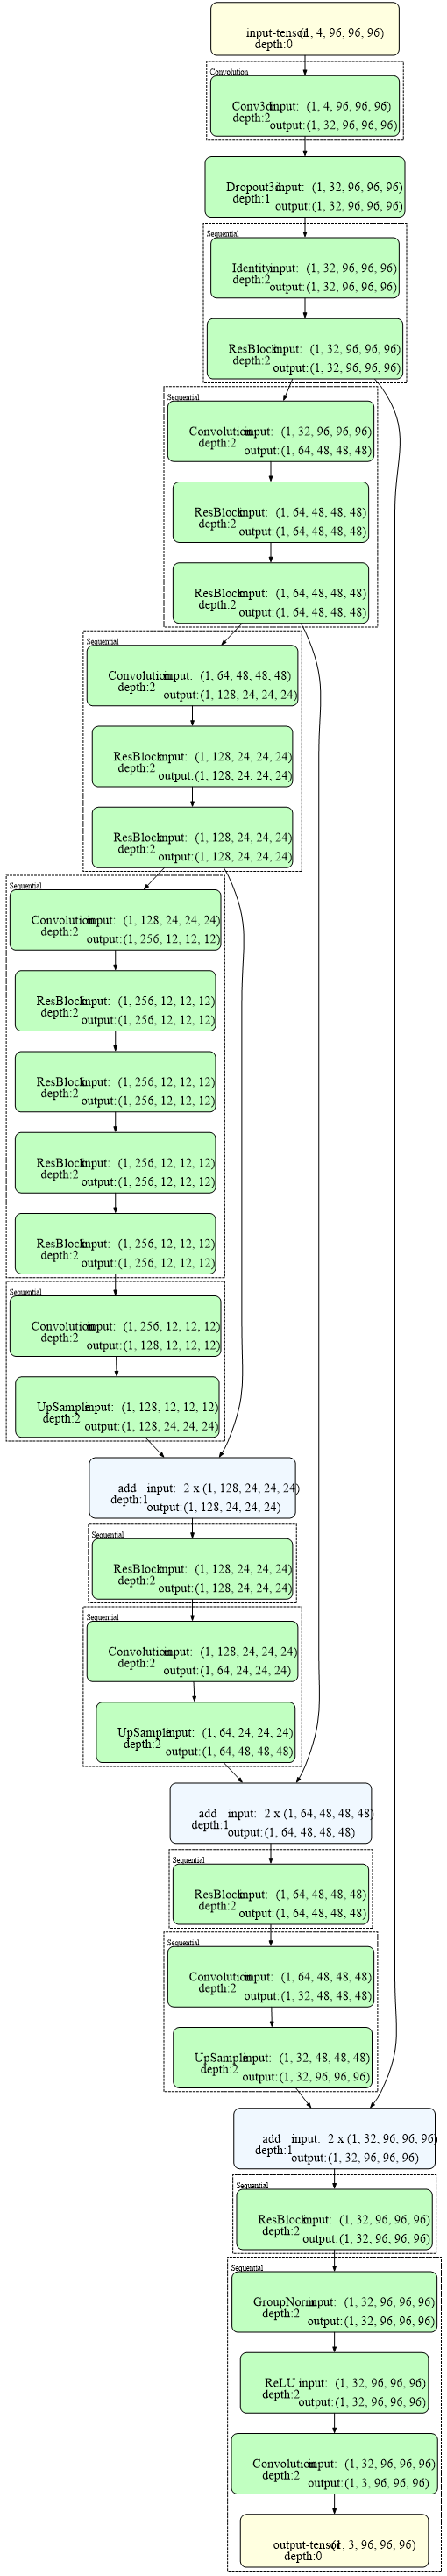

6158

In [13]:
def display_model_diagram(
    model, 
    input_shape=(1, 4, 96, 96, 96), 
    filename="segresnet_architecture",
    output_dir="./models_stage1"
):
    """Renders a clean vertical architecture diagram with explicit spacing for all layer blocks."""
    from torchview import draw_graph

    os.makedirs(output_dir, exist_ok=True)
    save_path = Path(output_dir) / filename

    print("\nGenerating model architecture diagram...")
    model_graph = draw_graph(
        model, 
        input_size=input_shape, 
        expand_nested=True, 
        depth=2,
        show_shapes=True,
        device="cpu",
        save_graph=False,
        filename=str(save_path),
        directory="."
    )
    
    visual_graph = model_graph.visual_graph
    
    # Set vertical flow layout
    visual_graph.attr(
        rankdir='TB',
        nodesep='0.4',
        ranksep='0.6',
        compound='true'
    )
    
    # Generous box dimensions
    visual_graph.node_attr.update(
        shape='box',
        style='filled,rounded',
        fixedsize='false',
        fontsize='20', # 11
        width='5.5',         
        margin='0.5,0.3'    
    )

    # Extract DOT source and aggressively strip all table and cluster container borders
    dot_source = visual_graph.source
    
    cleaned_dot = (
        dot_source
        .replace('BORDER="1"', 'BORDER="0"')
        .replace('cellborder="1"', 'cellborder="0"')
    )
    
    # Remove borders and backgrounds from subgraphs/clusters generated by nested expansion
    cleaned_dot = re.sub(r'color\s*=\s*"[^"]*"', 'color="none"', cleaned_dot, flags=re.IGNORECASE)
    cleaned_dot = re.sub(r'style\s*=\s*"[^"]*"\s*;', 'style="invis";', cleaned_dot, flags=re.IGNORECASE)

    # Patch HTML tables and cells for clean alignment and padding
    def patch_html_tags(match):
        tag = match.group(0)
        tag_name = match.group(1).upper()
        
        if tag_name == 'TABLE':
            tag = re.sub(r'\s+CELLSPACING="[^"]*"', '', tag, flags=re.IGNORECASE)
            tag = re.sub(r'\s+CELLPADDING="[^"]*"', '', tag, flags=re.IGNORECASE)
            return tag[:-1] + ' CELLSPACING="4" CELLPADDING="4">'
        elif tag_name == 'TD':
            tag = re.sub(r'\s+ALIGN="[^"]*"', '', tag, flags=re.IGNORECASE)
            tag = re.sub(r'\s+VALIGN="[^"]*"', '', tag, flags=re.IGNORECASE)
            tag = re.sub(r'\s+CELLPADDING="[^"]*"', '', tag, flags=re.IGNORECASE)
            return tag[:-1] + ' ALIGN="LEFT" VALIGN="TOP" CELLPADDING="6">'
        return tag

    cleaned_dot = re.sub(r'<(TABLE|TD)\b[^>]*>', patch_html_tags, cleaned_dot, flags=re.IGNORECASE)

    # Explicitly target all network layer names to guarantee a line break before attributes
    layer_names = r'(Convolution|GroupNorm|ResBlock|UpSample|Dropout3d|Identity|ReLU|Conv3d|add|output-tensor|input-tensor)'
    cleaned_dot = re.sub(layer_names + r'(?i)(input:|output:|depth:)', r'\1<BR/>\2', cleaned_dot)
    
    # Clean up any duplicate or messy line breaks
    cleaned_dot = re.sub(r'(<BR/>\s*)+', r'<BR/>', cleaned_dot, flags=re.IGNORECASE)

    # Render directly from the cleaned DOT string
    clean_graph = graphviz.Source(cleaned_dot)
    output_file = clean_graph.render(filename=filename, directory=output_dir, format="png", cleanup=True)
    
    png_file = f"{save_path}.png"
    if os.path.exists(png_file):
        print(f"Saved architecture diagram to: {png_file}")
        display(Image(filename=png_file))

# Instantiate temporary sample model for diagram generation
device = "cuda" if torch.cuda.is_available() else "cpu"
sample_model = SegResNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=3,
    init_filters=32, 
    blocks_down=[1, 2, 2, 4],
    blocks_up=[1, 1, 1],
    dropout_prob=0.2,
).to(device)

display_model_diagram(
    sample_model, 
    input_shape=(1, 4, 96, 96, 96),
    filename="segresnet_architecture",
    output_dir="./models_stage1")

# Cleanup sample model
del sample_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()

### Segmentation Model Training, Plotting, and Specifications

In [14]:
# Make sure to change overlap back to 0.5 and val_freq to 5 for final run
def update_live_plot(history, fold_idx, output_dir="./models_stage1", plot_handle=None, is_final=False):
    """Renders or updates the 3-panel training dashboard correctly in Jupyter without freezing."""
    epochs = [h["epoch"] for h in history]
    train_losses = [h["train_loss"] for h in history]
    val_dices = [h["val_dice"] for h in history]
    learning_rates = [h["lr"] for h in history]

    current_epoch = epochs[-1] if epochs else 0
    max_epochs = 100

    # Create figure or reuse existing one if passed via plot_handle (fixed typo check)
    if plot_handle is None or not hasattr(plot_handle, "fig") or not plt.fignum_exists(plot_handle.fig.number):
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))
    else:
        fig = plot_handle.fig
        fig.clf()
        ax1, ax2, ax3 = fig.subplots(1, 3)

    # Training Loss
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.plot(epochs, train_losses, label="Train Loss", color="tab:blue")
    ax1.set_title("Training Loss (Hybrid Dice-Focal)")
    ax1.legend(loc="upper right")
    ax1.grid(True, linestyle="--", alpha=0.5)

    # Validation Dice (with Best Marker)
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Mean Dice")
    valid_dices = [(e, d) for e, d in zip(epochs, val_dices) if not np.isnan(d)]
    
    if valid_dices:
        v_epochs, v_vals = zip(*valid_dices)
        ax2.plot(v_epochs, v_vals, marker="o", markersize=4, color="tab:green", label="Val Dice")
        
        # Highlight best validation dice
        best_val = max(v_vals)
        best_epoch = v_epochs[v_vals.index(best_val)]
        ax2.plot(best_epoch, best_val, marker="o", markersize=8, color="tab:red")
        ax2.scatter([], [], color="tab:red", label=f"Best: {best_val:.4f}")

    ax2.set_ylim(0.0, 1.0)
    ax2.set_title("Validation Mean Dice Score")
    ax2.legend(loc="lower right")
    ax2.grid(True, linestyle="--", alpha=0.5)

    # Learning Rate Schedule
    ax3.set_xlabel("Epoch")
    ax3.set_ylabel("LR")
    ax3.plot(epochs, learning_rates, color="tab:orange", label="Learning Rate")
    ax3.set_yscale("log")
    ax3.set_title("Learning Rate Schedule")
    ax3.legend(loc="upper right")
    ax3.grid(True, linestyle="--", alpha=0.5)

    fig.suptitle(f"Fold {fold_idx+1} Training Dashboard (SegResNet) — Epoch {current_epoch}/{max_epochs}", fontsize=12, fontweight="bold", y=1.03)
    fig.tight_layout()

    # Save final dashboard image as PNG to disk when training completes
    if is_final:
        dashboard_path = os.path.join(output_dir, f"segresnet_training_dashboard_fold_{fold_idx}.png")
        fig.savefig(dashboard_path, dpi=300, bbox_inches="tight")
        print(f"Saved training dashboard PNG image to {dashboard_path}")

    # Redraw canvas
    fig.canvas.draw()

    if plot_handle is not None and hasattr(plot_handle, "update"):
        plot_handle.update(fig)
        if is_final:
            plt.close(fig)
        return plot_handle
    else:
        handle = display(fig, display_id=True)
        handle.fig = fig  # Attach figure reference to handle
        return handle

def plot_cross_validation_results(output_dir="./models_stage1", num_folds=5):
    """Generates and saves a comparative 5-fold cross-validation performance summary plot."""
    fold_epochs = {}
    
    for fold in range(num_folds):
        metrics_csv_path = os.path.join(output_dir, f"fold_{fold}_metrics.csv")
        if os.path.exists(metrics_csv_path):
            try:
                df = pd.read_csv(metrics_csv_path)
                if "val_dice" in df.columns:
                    valid_subset = df.dropna(subset=["val_dice"])
                    if not valid_subset.empty:
                        fold_epochs[fold] = (valid_subset["epoch"], valid_subset["val_dice"])
            except Exception as e:
                print(f"Could not load metrics for Fold {fold}: {e}")

    if not fold_epochs:
        print("⚠️ No fold validation data found to generate summary plot.")
        return

    fig, ax = plt.subplots(figsize=(10, 6))
    
    for fold, (epochs, dices) in fold_epochs.items():
        peak_dice = dices.max()
        ax.plot(epochs, dices, marker="o", markersize=3, label=f"Fold {fold+1} (Peak: {peak_dice:.4f})", linewidth=2)

    ax.set_title("5-Fold Cross-Validation Validation Dice Curves (SegResNet)", fontsize=14, fontweight="bold")
    ax.set_xlabel("Epoch", fontsize=12)
    ax.set_ylabel("Validation Mean Dice Score", fontsize=12)
    ax.set_ylim(0.0, 1.0)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="lower right", fontsize=10)
    
    fig.tight_layout()
    summary_plot_path = os.path.join(output_dir, "segresnet_cv_all_folds_summary.png")
    fig.savefig(summary_plot_path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved 5-fold cross-validation summary plot to {summary_plot_path}")

def train_fold(
    fold_idx,
    df_cv,
    data_dir,
    output_dir,
    max_epochs=100,
    val_interval=10,
    batch_size=1,
    accumulation_steps=2,
    lr=1e-4,
):
    """Executes high-performance training with robust resumption and clean scheduler handling."""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[Fold {fold_idx+1}] Using device: {device}")

    # Split dataset based on fold index column
    train_df = df_cv[df_cv["fold"] != fold_idx]
    val_df = df_cv[df_cv["fold"] == fold_idx]

    def build_file_dicts(df):
        files = []
        for _, row in df.iterrows():
            patient_dir = row["image_dir"]
            if not os.path.isabs(patient_dir) and not os.path.exists(patient_dir):
                patient_dir = os.path.join(data_dir, patient_dir)

            label_matches = glob.glob(os.path.join(patient_dir, "*seg.nii.gz")) + \
                            glob.glob(os.path.join(patient_dir, "*seg.nii"))
            
            if not label_matches:
                continue
            label_path = label_matches[0]

            t1n = glob.glob(os.path.join(patient_dir, "*t1n.nii*"))[0]
            t1c = glob.glob(os.path.join(patient_dir, "*t1c.nii*"))[0]
            t2f = glob.glob(os.path.join(patient_dir, "*t2f.nii*"))[0]
            t2w = glob.glob(os.path.join(patient_dir, "*t2w.nii*"))[0]

            files.append({
                "image": [t1n, t1c, t2f, t2w],
                "label": label_path
            })
        return files

    train_files = build_file_dicts(train_df)
    val_files = build_file_dicts(val_df)

    print(f"[Fold {fold_idx+1}] Loaded {len(train_files)} training files and {len(val_files)} validation files.")

    train_transforms, val_transforms = get_transforms()

    train_ds = Dataset(data=train_files, transform=train_transforms)
    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True, 
        num_workers=4, pin_memory=True, persistent_workers=True
    )

    val_cache_dir = os.path.join(output_dir, f"val_cache_fold_{fold_idx}")
    os.makedirs(val_cache_dir, exist_ok=True)
    
    val_ds = PersistentDataset(
        data=val_files, 
        transform=val_transforms, 
        cache_dir=val_cache_dir
    )
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=4, pin_memory=True)

    print(f"[Fold {fold_idx+1}] Pre-warming validation cache to disk...")
    for _ in val_loader:
        pass
    print(f"[Fold {fold_idx+1}] Validation cache is ready.")

    model = SegResNet(
        spatial_dims=3,
        in_channels=4,
        out_channels=3,
        init_filters=32,
        blocks_down=[1, 2, 2, 4],
        blocks_up=[1, 1, 1],
        dropout_prob=0.2,
    ).to(device)

    best_ckpt_path = os.path.join(output_dir, f"segresnet_fold_{fold_idx}.pt")
    latest_ckpt_path = os.path.join(output_dir, f"segresnet_fold_{fold_idx}_latest.pt")
    metrics_csv_path = os.path.join(output_dir, f"fold_{fold_idx}_metrics.csv")

    start_epoch = 0
    history = []
    best_val_dice = -1.0

    # --- BULLETPROOF RESUMPTION & WEIGHT SYNC ---
    if os.path.exists(metrics_csv_path):
        try:
            df_history = pd.read_csv(metrics_csv_path)
            if not df_history.empty:
                history = df_history.to_dict("records")
                csv_max_epoch = int(df_history["epoch"].max())
                best_val_dice = float(df_history["val_dice"].dropna().max()) if not df_history["val_dice"].dropna().empty else -1.0
        except Exception as e:
            print(f"Error parsing history CSV ({e}). Starting fresh from epoch 0.")

    # Only resume if the latest checkpoint exists to match the CSV history
    if os.path.exists(latest_ckpt_path) and len(history) > 0:
        model.load_state_dict(torch.load(latest_ckpt_path, map_location=device, weights_only=True))
        start_epoch = int(df_history["epoch"].max())
        print(f"Resumed cleanly from LATEST checkpoint at epoch {start_epoch} ({latest_ckpt_path})")
    else:
        if os.path.exists(metrics_csv_path) or os.path.exists(latest_ckpt_path):
            print(f"Latest checkpoint missing or mismatched with history. Starting fresh from epoch 0 to prevent weight desync.")
        start_epoch = 0
        history = []
        best_val_dice = -1.0

    # Initialize optimizer
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    
    for group in optimizer.param_groups:
        group.setdefault('initial_lr', lr)

    # Initialize scheduler with correct last_epoch state
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max_epochs, last_epoch=start_epoch - 1 if start_epoch > 0 else -1
    )

    loss_function = DiceFocalLoss(
        smooth_nr=1e-5, smooth_dr=1e-5, squared_pred=True, to_onehot_y=False, sigmoid=True
    )
    dice_metric = DiceMetric(include_background=False, reduction="mean")

    scaler = torch.amp.GradScaler("cuda")

    plot_handle = update_live_plot(history, fold_idx, output_dir=output_dir)

    for epoch in range(start_epoch, max_epochs):
        model.train()
        epoch_loss = 0.0
        step_count = 0

        optimizer.zero_grad()
        for batch_idx, batch_data in enumerate(train_loader):
            inputs, targets = batch_data["image"].to(device, non_blocking=True), batch_data["label"].to(device, non_blocking=True)
            
            with torch.amp.autocast("cuda"):
                outputs = model(inputs)
                loss = loss_function(outputs, targets)
                loss_scaled = loss / accumulation_steps

            scaler.scale(loss_scaled).backward()
            epoch_loss += loss.item()
            step_count += 1

            if (batch_idx + 1) % accumulation_steps == 0 or (batch_idx + 1) == len(train_loader):
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()

        current_lr = optimizer.param_groups[0]["lr"]
        scheduler.step()
        epoch_loss = epoch_loss / step_count if step_count > 0 else 0.0

        val_dice = np.nan
        if (epoch + 1) % val_interval == 0 or (epoch + 1) == max_epochs:
            model.eval()
            with torch.no_grad():
                for val_data in val_loader:
                    val_inputs, val_targets = val_data["image"].to(device, non_blocking=True), val_data["label"].to(device, non_blocking=True)
                    
                    with torch.amp.autocast("cuda"):
                        val_outputs = sliding_window_inference(
                            val_inputs, roi_size=(96, 96, 96), sw_batch_size=4, predictor=model, overlap=0.35
                        )
                    
                    val_outputs = (val_outputs.sigmoid() > 0.5).float()
                    dice_metric(y_pred=val_outputs, y=val_targets)

                val_dice = dice_metric.aggregate().item()
                dice_metric.reset()

            print(f"Epoch {epoch+1}/{max_epochs} | Train Loss: {epoch_loss:.4f} | Val Dice: {val_dice:.4f} | LR: {current_lr:.6f}")

            if val_dice > best_val_dice:
                best_val_dice = val_dice
                torch.save(model.state_dict(), best_ckpt_path)
                print(f"Saved new BEST model checkpoint to {best_ckpt_path}")

        # Save latest epoch checkpoint after every epoch
        torch.save(model.state_dict(), latest_ckpt_path)

        history.append({
            "fold": fold_idx,
            "epoch": epoch + 1, 
            "train_loss": epoch_loss, 
            "val_dice": val_dice, 
            "lr": current_lr
        })
        
        pd.DataFrame(history).to_csv(metrics_csv_path, index=False)
        plot_handle = update_live_plot(history, fold_idx, output_dir=output_dir, plot_handle=plot_handle, is_final=False)

    update_live_plot(history, fold_idx, output_dir=output_dir, plot_handle=plot_handle, is_final=True)

    # Clean up temporary latest checkpoint once fold is successfully finished
    if os.path.exists(latest_ckpt_path):
        os.remove(latest_ckpt_path)
        print(f"[Fold {fold_idx+1}] Cleaned up temporary latest checkpoint.")

    return best_val_dice, best_ckpt_path

In [15]:
if __name__ == "__main__":
    # Enable cuDNN auto-tuner & TensorFloat32 (TF32) precision for Ampere (RTX 3060)
    torch.backends.cudnn.benchmark = True
    torch.set_float32_matmul_precision('high')
    torch.backends.cudnn.allow_tf32 = True

    # Path configurations for BraTS 2023 dataset structure
    data_directory = "C:/BraTS2023/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData"
    csv_pool_path = "./models_stage1/brats_cv_pool_5fold.csv"
    output_directory = "./models_stage1"  

    # Fallback path resolutions if needed
    if not os.path.exists(csv_pool_path):
        if os.path.exists("brats_cv_pool_5fold.csv"):
            csv_pool_path = "brats_cv_pool_5fold.csv"
        else:
            csv_pool_path = "brats_cv_pool_preprocessed.csv"

    os.makedirs(output_directory, exist_ok=True)
    df_cv = pd.read_csv(csv_pool_path)

    print(f"Loaded CV Pool from '{csv_pool_path}' with {len(df_cv)} records and columns: {list(df_cv.columns)}")
    fold_results = {}
    max_epochs = 100
    num_folds = 2 # 5 later

    # Train 5 Folds sequentially (0 through 4)
    for fold in range(num_folds):
        metrics_csv_path = os.path.join(output_directory, f"fold_{fold}_metrics.csv")
        ckpt_path = os.path.join(output_directory, f"segresnet_fold_{fold}.pt")

        # RESUME LOGIC: Skip only if fully complete
        if os.path.exists(metrics_csv_path) and os.path.exists(ckpt_path):
            try:
                df_hist = pd.read_csv(metrics_csv_path)
                completed_epochs = len(df_hist)
                
                if completed_epochs >= max_epochs:
                    valid_dices = df_hist["val_dice"].dropna()
                    best_dice = float(valid_dices.max()) if not valid_dices.empty else 0.0
                    print(f"\n[Fold {fold+1}/{num_folds}] Already complete ({completed_epochs}/{max_epochs} epochs logged). Peak Val Dice: {best_dice:.4f}. Skipping...")
                    fold_results[fold] = {
                        "best_dice": best_dice,
                        "ckpt_path": ckpt_path
                    }
                    continue
            except Exception as e:
                print(f"[Fold {fold}] Existing metrics log unreadable ({e}). Re-running fold from scratch...")
        
        print(f"\n================ Starting Fold {fold+1}/{num_folds} ================")

        try:
            best_dice, model_path = train_fold(
                fold_idx=fold,
                df_cv=df_cv,
                data_dir=data_directory,
                output_dir=output_directory,
                max_epochs=max_epochs,
                val_interval=10, 
                batch_size=1,
                accumulation_steps=2,
                lr=1e-4
            )

            fold_results[fold] = {
                "best_dice": best_dice,
                "ckpt_path": model_path
            }
        except Exception as e:
            print(f"\n Exception occurred during Fold {fold}: {e}")
            print("Skipping to memory cleanup...\n")

        # Clear VRAM and trigger Python garbage collection between folds
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.ipc_collect()
        gc.collect()

        print(f"[Fold {fold}] Memory cleanup complete.\n")

    # CROSS-VALIDATION SUMMARY & BEST MODEL SELECTION
    if fold_results:
        print("\n" + "=" * 60)
        print("        5-FOLD CROSS-VALIDATION SUMMARY (SEGRESNET)")
        print("=" * 60)

        best_fold_idx = max(fold_results, key=lambda k: fold_results[k]["best_dice"])

        for fold, res in sorted(fold_results.items()):
            tag = " BEST MODEL" if fold == best_fold_idx else ""
            print(f"Fold {fold}: Peak Val Dice = {res['best_dice']:.4f} | {res['ckpt_path']} {tag}")

        avg_cv_dice = np.mean([res["best_dice"] for res in fold_results.values()])
        std_cv_dice = np.std([res["best_dice"] for res in fold_results.values()])

        print("-" * 60)
        print(f"Mean CV Dice Score : {avg_cv_dice:.4f} ± {std_cv_dice:.4f}")
        print(f"RECOMMENDED MODEL  : Fold {best_fold_idx} ({fold_results[best_fold_idx]['ckpt_path']})")
        print("=" * 60 + "\n")

        # Export summary JSON
        summary_data = {
            "mean_cv_dice": float(avg_cv_dice),
            "std_cv_dice": float(std_cv_dice),
            "best_fold": int(best_fold_idx),
            "best_checkpoint": fold_results[best_fold_idx]["ckpt_path"],
            "fold_scores": {int(k): float(v["best_dice"]) for k, v in fold_results.items()}
        }
        summary_file = os.path.join(output_directory, "segresnet_cv_summary.json")
        with open(summary_file, "w") as f:
            json.dump(summary_data, f, indent=4)
        print(f"Saved CV summary to: {summary_file}\n")

        if "plot_cross_validation_results" in globals():
            plot_cross_validation_results(output_dir=output_directory, num_folds=num_folds)
    else:
        print("\nNo completed fold results found to generate summary.")
        
# Running on silent mode for GPU health.

Loaded CV Pool from './models_stage1/brats_cv_pool_5fold.csv' with 1089 records and columns: ['image_dir', 'fold']

[Fold 1/2] Already complete (100/100 epochs logged). Peak Val Dice: 0.8845. Skipping...

[Fold 2/2] Already complete (100/100 epochs logged). Peak Val Dice: 0.8934. Skipping...

        5-FOLD CROSS-VALIDATION SUMMARY (SEGRESNET)
Fold 0: Peak Val Dice = 0.8845 | ./models_stage1\segresnet_fold_0.pt 
Fold 1: Peak Val Dice = 0.8934 | ./models_stage1\segresnet_fold_1.pt  BEST MODEL
------------------------------------------------------------
Mean CV Dice Score : 0.8890 ± 0.0045
RECOMMENDED MODEL  : Fold 1 (./models_stage1\segresnet_fold_1.pt)

Saved CV summary to: ./models_stage1\segresnet_cv_summary.json

Saved 5-fold cross-validation summary plot to ./models_stage1\segresnet_cv_all_folds_summary.png


### Test Set Infrence

In [ ]:
set_determinism(seed=42)

def get_test_transforms():
    """Defines preprocessing transforms matching the validation pipeline precisely."""
    return Compose([
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"]),
        ConvertToMultiChannelBasedOnBratsClassesd(keys="label"),
        Orientationd(keys=["image", "label"], axcodes="RAS", labels=None),
        Spacingd(
            keys=["image", "label"],
            pixdim=(1.0, 1.0, 1.0),
            mode=("bilinear", "nearest"),
        ),
        NormalizeIntensityd(keys="image", nonzero=True, channel_wise=True),
        EnsureTyped(keys=["image", "label"]),
    ])

def remove_small_connected_components_gpu(prediction_tensor, min_size=30):
    """
    Optimized connected component cleanup using PyTorch/SciPy hybrid 
    keeping computation vectorized where possible.
    """
    cleaned = prediction_tensor.clone()
    for c in range(cleaned.shape[0]):
        channel_data = cleaned[c].bool().cpu().numpy()
        labeled_array, num_features = label(channel_data)
        if num_features > 0:
            component_sizes = np.bincount(labeled_array.ravel())
            too_small = component_sizes < min_size
            too_small[0] = False  # Keep background
            remove_mask = too_small[labeled_array]
            cleaned[c][torch.from_numpy(remove_mask).to(cleaned.device)] = 0
    return cleaned

def convert_multichannel_to_brats_labels(multichannel_tensor):
    """Converts 3-channel binary tensor to BraTS standard integer label format."""
    tc = multichannel_tensor[0].cpu().numpy().astype(bool)
    wt = multichannel_tensor[1].cpu().numpy().astype(bool)
    et = multichannel_tensor[2].cpu().numpy().astype(bool)

    seg_out = np.zeros(tc.shape, dtype=np.uint8)
    seg_out[wt] = 2           # Edema
    seg_out[tc] = 1           # NCR/NET
    seg_out[et] = 4           # Enhancing tumor
    return seg_out

def run_ensemble_inference(
    test_csv_path,
    data_dir,
    model_dir="./models_stage1",
    num_folds=5,
    device="cuda" if torch.cuda.is_available() else "cpu"
):
    print("Initializing Optimized Ensembled Test Evaluation...")
    
    masks_output_dir = os.path.join(model_dir, "predicted_masks")
    os.makedirs(masks_output_dir, exist_ok=True)
    
    test_df = pd.read_csv(test_csv_path)
    
    def resolve_path(row, suffix_pattern):
        if "image_dir" in row and pd.notna(row["image_dir"]):
            p_dir = Path(row["image_dir"])
        else:
            p_dir = Path(data_dir) / str(row["BraTS2023ID"])
        matches = list(p_dir.glob(f"*{suffix_pattern}.nii*"))
        if matches:
            return str(matches[0])
        raise FileNotFoundError(f"Could not find suffix '{suffix_pattern}' for {row.get('BraTS2023ID')} in {p_dir}")

    test_files = []
    for _, row in test_df.iterrows():
        pid = str(row["BraTS2023ID"])
        test_files.append({
            "image": [
                resolve_path(row, "t1n"),
                resolve_path(row, "t1c"),
                resolve_path(row, "t2w"),
                resolve_path(row, "t2f"),
            ],
            "label": resolve_path(row, "seg"),
            "BraTS2023ID": pid
        })

    test_ds = Dataset(data=test_files, transform=get_test_transforms())
    test_loader = DataLoader(test_ds, batch_size=1, num_workers=2, pin_memory=True)

    models = []
    for fold in range(num_folds):
        ckpt_path = os.path.join(model_dir, f"segresnet_fold_{fold}.pt")
        if os.path.exists(ckpt_path):
            print(f"Loading SegResNet checkpoint for Fold {fold}: {ckpt_path}")
            model = SegResNet(
                spatial_dims=3,
                in_channels=4,
                out_channels=3,
                init_filters=32,  
                blocks_down=[1, 2, 2, 4],
                blocks_up=[1, 1, 1],
                dropout_prob=0.0,
            ).to(device)
            model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
            model.eval()
            models.append(model)
        else:
            print(f"Warning: Checkpoint for Fold {fold} not found at {ckpt_path}. Skipping.")

    if not models:
        raise ValueError("No valid model checkpoints found! Please verify model_dir.")

    dice_metric = DiceMetric(include_background=False, reduction="mean") # Aligned with training metric
    post_sigmoid = torch.nn.Sigmoid()
    post_pred = Compose([AsDiscrete(argmax=False, threshold=0.5)])

    test_results = []
    flip_axes_list = [None, 2, 3, 4]

    print(f"\nRunning optimized inference across {len(models)} models on {len(test_loader)} test samples...")
    
    with torch.no_grad():
        for batch_data in tqdm(test_loader, desc="Optimized Inference Progress"):
            test_inputs = batch_data["image"].to(device, non_blocking=True)
            test_labels = batch_data["label"].cpu()
            pid = batch_data["BraTS2023ID"][0]

            fold_outputs = []
            
            for model in models:
                tta_probs = []
                for axis in flip_axes_list:
                    current_input = torch.flip(test_inputs, dims=[axis]) if axis is not None else test_inputs

                    with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                        val_outputs = sliding_window_inference(
                            inputs=current_input, 
                            roi_size=(96, 96, 96),  
                            sw_batch_size=4,        
                            overlap=0.25,            
                            predictor=model,
                            device=device
                        )
                        probs = post_sigmoid(val_outputs)

                    if axis is not None:
                        probs = torch.flip(probs, dims=[axis])
                    tta_probs.append(probs)

                model_mean_probs = torch.stack(tta_probs).mean(dim=0)
                fold_outputs.append(model_mean_probs)

            ensemble_probs = torch.stack(fold_outputs).mean(dim=0)[0]  # [C, H, W, D]

            cleaned_probs = remove_small_connected_components_gpu(ensemble_probs, min_size=30)
            ensemble_outputs = [post_pred(cleaned_probs.cpu())]
            target_labels = decollate_batch(test_labels)

            dice_metric(y_pred=ensemble_outputs, y=target_labels)
            sample_dice = dice_metric.aggregate().item()
            dice_metric.reset()

            pred_multichannel_tensor = ensemble_outputs[0]
            pred_label_arr = convert_multichannel_to_brats_labels(pred_multichannel_tensor)
            
            row_match = test_df[test_df["BraTS2023ID"] == pid].iloc[0]
            ref_nii_path = resolve_path(row_match, "t1c")
            ref_nii = nib.load(ref_nii_path)
            
            pred_nii = nib.Nifti1Image(pred_label_arr.astype(np.uint8), affine=ref_nii.affine, header=ref_nii.header)
            save_mask_path = os.path.join(masks_output_dir, f"{pid}_pred.nii.gz")
            nib.save(pred_nii, save_mask_path)

            test_results.append({
                "BraTS2023ID": pid,
                "ensemble_dice": sample_dice
            })
            print(f"Sample {pid} | Ensemble Dice: {sample_dice:.4f}")

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results_df = pd.DataFrame(test_results)
    mean_test_dice = results_df["ensemble_dice"].mean()
    std_test_dice = results_df["ensemble_dice"].std()

    print("\n" + "=" * 50)
    print("    OPTIMIZED ENSEMBLE TEST SET RESULTS")
    print("=" * 50)
    print(f"Mean Test Dice Score : {mean_test_dice:.4f} ± {std_test_dice:.4f}")
    print("=" * 50)

    output_csv = os.path.join(model_dir, "segresnet_advanced_ensemble_test_results.csv")
    results_df.to_csv(output_csv, index=False)

    fig = make_subplots(rows=1, cols=2, subplot_titles=("Dice Distribution", "Frequency Histogram"))
    fig.add_trace(go.Box(y=results_df["ensemble_dice"], name="Test Dice", boxmean=True, marker_color="#1f77b4"), row=1, col=1)
    fig.add_trace(go.Histogram(x=results_df["ensemble_dice"], name="Frequency", marker_color="#2ca02c", nbinsx=15), row=1, col=2)
    fig.update_layout(title_text="BraTS Test Performance (Optimized)", template="plotly_white", showlegend=False, height=500, width=1000)
    
    fig.write_html(os.path.join(model_dir, "segresnet_test_dice_distribution.html"))
    fig.show()

if __name__ == "__main__":
    DATA_DIR = "C:/BraTS2023/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData"
    TEST_CSV = "./models_stage1/brats_ablation_test_set_166.csv"  
    
    run_ensemble_inference(
        test_csv_path=TEST_CSV,
        data_dir=DATA_DIR,
        model_dir="./models_stage1",
        num_folds=2) # 5 later

Sample BraTS-GLI-00100-000 | Ensemble Dice: 0.8872
Sample BraTS-GLI-00102-000 | Ensemble Dice: 0.6171
Sample BraTS-GLI-00104-000 | Ensemble Dice: 0.8040
Sample BraTS-GLI-00105-000 | Ensemble Dice: 0.8735
Sample BraTS-GLI-00106-000 | Ensemble Dice: 0.9034
Sample BraTS-GLI-00107-000 | Ensemble Dice: 0.8915
Sample BraTS-GLI-00108-000 | Ensemble Dice: 0.8574
Sample BraTS-GLI-00109-000 | Ensemble Dice: 0.8366
Sample BraTS-GLI-00110-000 | Ensemble Dice: 0.9389
Sample BraTS-GLI-00111-000 | Ensemble Dice: 0.8327
Sample BraTS-GLI-00113-000 | Ensemble Dice: 0.2292
Sample BraTS-GLI-00116-000 | Ensemble Dice: 0.8005
Sample BraTS-GLI-00117-000 | Ensemble Dice: 0.7935
Sample BraTS-GLI-00120-000 | Ensemble Dice: 0.7789
Sample BraTS-GLI-00121-000 | Ensemble Dice: 0.8169
Sample BraTS-GLI-00122-000 | Ensemble Dice: 0.4791
Sample BraTS-GLI-00123-000 | Ensemble Dice: 0.8928
Sample BraTS-GLI-00124-000 | Ensemble Dice: 0.1108
Sample BraTS-GLI-00128-000 | Ensemble Dice: 0.9060
Sample BraTS-GLI-00130-000 | En

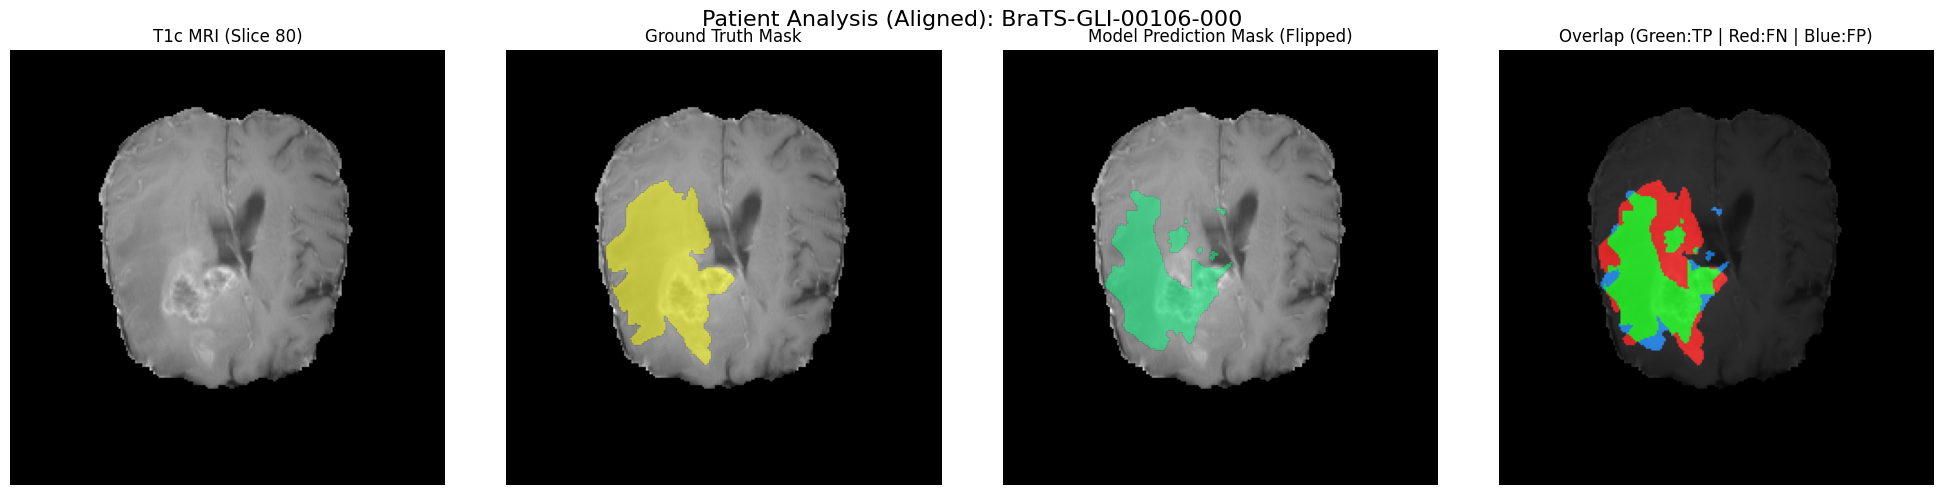

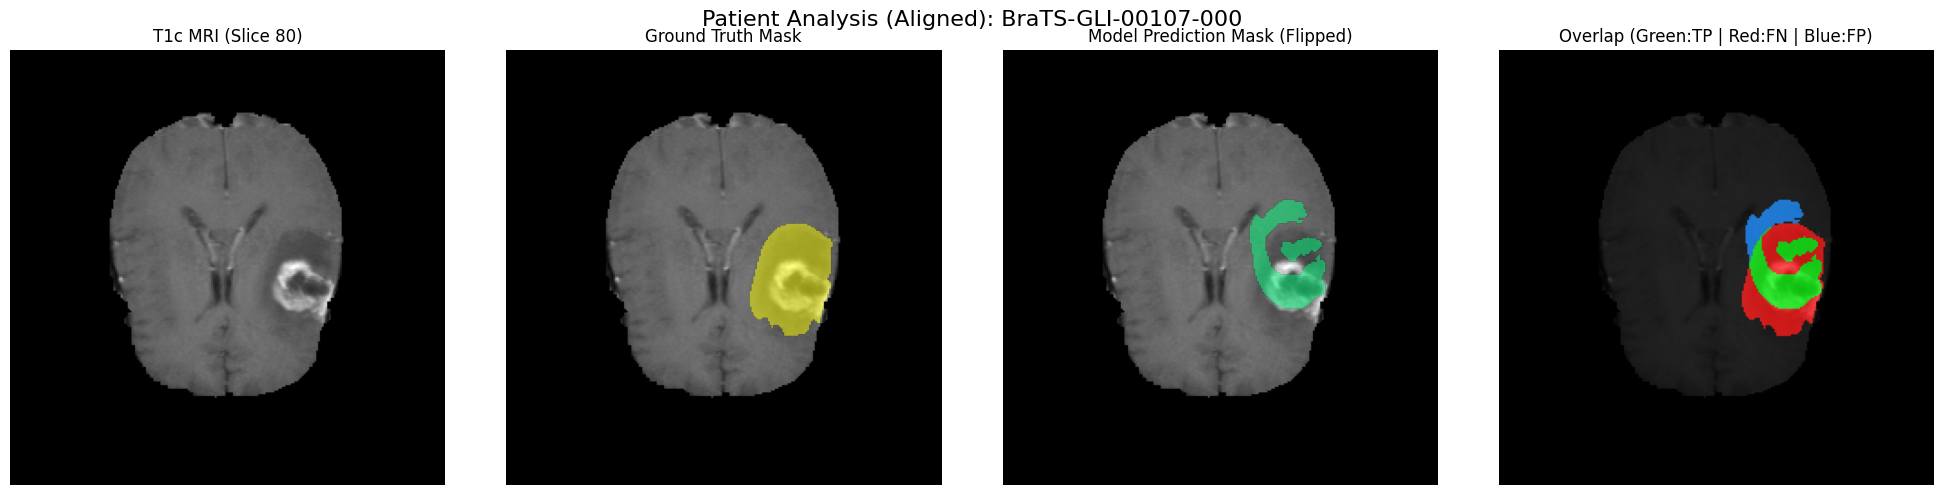

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import nibabel as nib
import os

def plot_inference_comparison_fixed(patient_id: str, model_dir="./models_stage1", slice_idx=75):
    masks_dir = os.path.join(model_dir, "predicted_masks")
    pred_path = os.path.join(masks_dir, f"{patient_id}_pred.nii.gz")
    
    if not os.path.exists(pred_path):
        print(f"Prediction mask not found for {patient_id} at {pred_path}.")
        return

    paths = get_patient_nifti_paths(patient_id)
    if not paths or "t1ce" not in paths or "seg" not in paths:
        print(f"Could not find source files for {patient_id}")
        return

    # Load raw volumes
    t1c_img = nib.load(str(paths["t1ce"])).get_fdata()
    gt_img = nib.load(str(paths["seg"])).get_fdata()
    pred_img = nib.load(pred_path).get_fdata()

    # Safety check for slice index bounds
    max_slice = t1c_img.shape[2] - 1
    if slice_idx > max_slice:
        print(f"Warning: slice_idx {slice_idx} exceeds max depth {max_slice} for {patient_id}. Clipping to {max_slice // 2}.")
        slice_idx = max_slice // 2

    # Extract 2D axial slices and transpose for display
    slice_bg = t1c_img[:, :, slice_idx].T
    slice_gt = (gt_img[:, :, slice_idx] > 0).astype(np.float32).T
    
    # Apply horizontal flip to correct the saved affine mismatch from inference
    slice_pred = np.fliplr((pred_img[:, :, slice_idx] > 0).astype(np.float32).T)

    # Mask background zeros for transparency
    slice_gt_masked = np.ma.masked_where(slice_gt == 0, slice_gt)
    slice_pred_masked = np.ma.masked_where(slice_pred == 0, slice_pred)

    # Compute Overlap Map (TP: Green, FP: Blue, FN: Red)
    overlap_map = np.zeros((*slice_bg.shape, 3), dtype=np.float32)
    tp = (slice_gt == 1) & (slice_pred == 1)
    fp = (slice_gt == 0) & (slice_pred == 1)
    fn = (slice_gt == 1) & (slice_pred == 0)

    overlap_map[tp] = [0.0, 1.0, 0.0]  # Green: True Positive
    overlap_map[fp] = [0.0, 0.5, 1.0]  # Blue: False Positive
    overlap_map[fn] = [1.0, 0.0, 0.0]  # Red: False Negative
    
    overlap_masked = np.ma.masked_where(~(tp | fp | fn)[..., None].repeat(3, axis=-1), overlap_map)

    # Plotting
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    axes[0].imshow(slice_bg, cmap="gray", origin="lower")
    axes[0].set_title(f"T1c MRI (Slice {slice_idx})")
    
    axes[1].imshow(slice_bg, cmap="gray", origin="lower")
    axes[1].imshow(slice_gt_masked, cmap="autumn", alpha=0.5, origin="lower", vmin=0, vmax=1)
    axes[1].set_title("Ground Truth Mask")
    
    axes[2].imshow(slice_bg, cmap="gray", origin="lower")
    axes[2].imshow(slice_pred_masked, cmap="winter", alpha=0.5, origin="lower", vmin=0, vmax=1)
    axes[2].set_title("Model Prediction Mask (Flipped)")
    
    axes[3].imshow(slice_bg, cmap="gray", origin="lower")
    axes[3].imshow(overlap_masked, alpha=0.7, origin="lower")
    axes[3].set_title("Overlap (Green:TP | Red:FN | Blue:FP)")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(f"Patient Analysis (Aligned): {patient_id}", fontsize=16)
    plt.tight_layout()
    plt.show()

# Corrected function call names
plot_inference_comparison_fixed("BraTS-GLI-00106-000", slice_idx=80)
plot_inference_comparison_fixed("BraTS-GLI-00107-000", slice_idx=80)

## Feature Extraction and Selection

In [ ]:
# Completely silence all PyRadiomics internal loggers and remove their handlers
for logger_name in logging.root.manager.loggerDict:
    if "radiomics" in logger_name:
        lg = logging.getLogger(logger_name)
        lg.setLevel(logging.CRITICAL)
        lg.propagate = False
        lg.handlers = []

# Also catch the root radiomics logger
rad_logger = logging.getLogger("radiomics")
rad_logger.setLevel(logging.CRITICAL)
rad_logger.propagate = False
rad_logger.handlers = []
def drop_redundant_glcm_features(df):
    """
    Drops redundant GLCM features (e.g., removing SumAverage due to 
    exact mathematical symmetry in symmetrical GLCMs).
    """
    if df.empty:
        return df
    
    cols_to_drop = [col for col in df.columns if 'glcm_SumAverage' in col]
    if cols_to_drop:
        df = df.drop(columns=cols_to_drop)
        print(f"🧹 Dropped {len(cols_to_drop)} redundant SumAverage GLCM feature(s) due to symmetry.")
        
    return df

def extract_separate_radiomics(
    image_dir="C:/BraTS2023/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData",
    pred_mask_dir="./models_stage1/predicted_masks",
    output_dir="./models_stage1/radiomics_results",
    modalities=["t1n", "t1c", "t2f", "t2w"]
):
    """
    Extracts optimized PyRadiomics features independently for predicted masks and ground truth segmentations,
    disabling heavy LBP/exponential filters and removing redundant symmetrical GLCM features.
    """
    os.makedirs(output_dir, exist_ok=True)
    
    # Configure extractor safely to prevent infinite hanging / extreme bottlenecks
    extractor = featureextractor.RadiomicsFeatureExtractor()
    extractor.disableAllImageTypes()
    extractor.disableAllFeatures()
    
    # Enable only essential image types (Original + LoG)
    extractor.enableImageTypeByName('Original')
    extractor.enableImageTypeByName('LoG', customArgs={'sigma': [1.0, 2.0, 3.0]}) # Safe scale-space filtering
    
    # Enable robust feature classes
    extractor.enableFeatureClassByName('shape')
    extractor.enableFeatureClassByName('firstorder')
    extractor.enableFeatureClassByName('glcm')
    extractor.enableFeatureClassByName('glrlm')
    extractor.enableFeatureClassByName('glszm')
    extractor.enableFeatureClassByName('ngtdm')

    pred_mask_paths = glob.glob(os.path.join(pred_mask_dir, "*_pred.nii*"))
    if not pred_mask_paths:
        print(f"No predicted masks found in {pred_mask_dir}")
        return pd.DataFrame(), pd.DataFrame()

    print(f"Found {len(pred_mask_paths)} predicted masks to process.")

    pred_results = []
    gt_results = []

    for pred_path in pred_mask_paths:
        basename = os.path.basename(pred_path)
        patient_id = basename.split("_")[0] 
        
        patient_folder_pattern = os.path.join(image_dir, f"*{patient_id}*")
        matched_folders = glob.glob(patient_folder_pattern)
        
        if not matched_folders:
            print(f"Could not find raw image directory for patient {patient_id}")
            continue
            
        patient_path = matched_folders[0]
        gt_matches = glob.glob(os.path.join(patient_path, "*seg.nii*"))
        gt_mask_path = gt_matches[0] if gt_matches else None

        if not gt_mask_path or not os.path.exists(gt_mask_path):
            print(f"Ground truth segmentation missing for {patient_id}. Skipping.")
            continue

        print(f"\nProcessing patient: {patient_id}")

        for mod in modalities:
            img_matches = glob.glob(os.path.join(patient_path, f"*{mod}.nii*"))
            if not img_matches:
                continue
            img_path = img_matches[0]

            # Extract features from Ground Truth Mask
            try:
                gt_features = extractor.execute(img_path, gt_mask_path, label=1)
                gt_row = {k: v for k, v in gt_features.items() if not k.startswith("diagnostics")}
                gt_row.update({"patient_id": patient_id, "modality": mod})
                gt_results.append(gt_row)
            except Exception as e:
                print(f"Error extracting GT radiomics for {patient_id} ({mod}): {e}")

            # Extract features from Predicted Mask
            try:
                pred_features = extractor.execute(img_path, pred_path, label=1)
                pred_row = {k: v for k, v in pred_features.items() if not k.startswith("diagnostics")}
                pred_row.update({"patient_id": patient_id, "modality": mod})
                pred_results.append(pred_row)
            except Exception as e:
                print(f"Error extracting Prediction radiomics for {patient_id} ({mod}): {e}")

    df_gt = pd.DataFrame(gt_results) if gt_results else pd.DataFrame()
    df_pred = pd.DataFrame(pred_results) if pred_results else pd.DataFrame()
    
    # Clean redundant GLCM features due to symmetry
    df_gt = drop_redundant_glcm_features(df_gt)
    df_pred = drop_redundant_glcm_features(df_pred)
    
    gt_csv_path = os.path.join(output_dir, "brats_groundtruth_radiomics_raw.csv")
    pred_csv_path = os.path.join(output_dir, "brats_predicted_radiomics_raw.csv")
    
    df_gt.to_csv(gt_csv_path, index=False)
    df_pred.to_csv(pred_csv_path, index=False)
    
    print(f"\nRaw Ground Truth saved to: {gt_csv_path}")
    print(f"Raw Predicted saved to: {pred_csv_path}")
    
    return df_pred, df_gt

# Run Extraction Cell
df_pred_raw, df_gt_raw = extract_separate_radiomics()

Found 42 predicted masks to process.

Processing patient: BraTS-GLI-00100-000


Dimensionality Reduction: Sparse PCA vs. UMAPSparse PCA for Interpretability: Using Sparse PCA introduces an L1 penalty on the component loadings, forcing many coefficients to zero. This makes the resulting components much easier to interpret clinically, as each principal component is driven by a distinct, sparse subset of radiomic features rather than a dense linear combination of all 400+ features.Alternative Non-Linear Methods: As noted, radiomic texture and shape features often exhibit complex, non-linear interactions. If the primary goal was exploration or non-linear feature extraction for downstream clustering/classification rather than linear interpretability, manifold learning techniques like UMAP (Uniform Manifold Approximation and Projection) or t-SNE would capture high-dimensional geometric structures much more effectively than linear PCA variants.

In [ ]:
def apply_sparse_pca_to_raw(pred_df_in, gt_df_in, n_components=20, id_cols=["patient_id", "modality"], alpha_spca=1.0):
    """
    Applies standardization and Sparse PCA on the raw feature tables, projecting 
    both predicted and ground truth datasets into an initial pool of interpretable components.
    """
    pred_df = pred_df_in.copy() if isinstance(pred_df_in, pd.DataFrame) else pd.read_csv(pred_df_in)
    gt_df = gt_df_in.copy() if isinstance(gt_df_in, pd.DataFrame) else pd.read_csv(gt_df_in)
    
    active_id_cols = [col for col in id_cols if col in pred_df.columns]
    feature_cols = [c for c in pred_df.select_dtypes(include=[np.number]).columns if c not in active_id_cols]
    
    X_pred_subset = pred_df[feature_cols].fillna(0)
    X_gt_subset = gt_df[feature_cols].fillna(0)
    
    # Standardize (fit on predicted, transform both)
    scaler = StandardScaler()
    X_pred_scaled = scaler.fit_transform(X_pred_subset)
    X_gt_scaled = scaler.transform(X_gt_subset)
    
    spca = SparsePCA(
        n_components=n_components, 
        alpha=alpha_spca, 
        random_state=42, 
        max_iter=1000, 
        n_jobs=-1)
    
    X_pred_spca = spca.fit_transform(X_pred_scaled)
    X_gt_spca = spca.transform(X_gt_scaled)
    
    component_cols = [f"SPCA_Component_{i+1}" for i in range(n_components)]
    
    spca_pred_df = pd.DataFrame(X_pred_spca, columns=component_cols)
    spca_gt_df = pd.DataFrame(X_gt_spca, columns=component_cols)
    
    for col in active_id_cols:
        spca_pred_df.insert(0, col, pred_df[col].values)
        spca_gt_df.insert(0, col, gt_df[col].values)
        
    print(f"=== Sparse PCA Extraction Complete ===")
    print(f"Generated {n_components} latent components from {len(feature_cols)} raw features.")
    
    return spca_pred_df, spca_gt_df, spca.components_, feature_cols

# Run Sparse PCA Cell using outputs from Cell 1
if 'df_pred_raw' in locals() and not df_pred_raw.empty:
    df_pred_spca, df_gt_spca, raw_loadings, raw_feature_names = apply_sparse_pca_to_raw(
        pred_df_in=df_pred_raw,
        gt_df_in=df_gt_raw,
        n_components=20,       # Initial candidate component pool
        id_cols=["patient_id", "modality"],
        alpha_spca=1.0
    )
else:
    print("Please execute Cell 1 first to generate raw feature tables.")

Variance: Measures overall dispersion to ensure features carry sufficient signal and aren't near-constant.

Coefficient of Variation (CoV): Evaluates relative variability (standard deviation divided by the mean) to gauge feature stability across patients.

Shapiro-Wilk Test: Tests whether the feature values conform to a normal distribution across the sample cohort.

Statistical Ranking: Every feature vector in the CSV is scored using variance, coefficient of variation, and normality tests, producing an overall informativeness score.Greedy Filtering: The code evaluates the sorted list starting from rank 1.Redundancy Pruning: If feature 2 or 3 is highly correlated ($> 0.85$) with feature 1, it is skipped. The algorithm automatically skips down to evaluate features 4, 5, 6, and beyond, ensuring your final set contains orthogonal (non-redundant) signals while preserving the highest statistical significance possible.

In [ ]:
def evaluate_and_filter_pca_components(pred_spca_df, gt_spca_df, top_k=8, id_cols=["patient_id", "modality"], corr_threshold=0.85):
    """
    Evaluates Sparse PCA component vectors using 3 statistical tests:
        - Variance (Dispersion)
        - Coefficient of Variation (Relative stability)
        - Shapiro-Wilk Test (Normality check -> shapiro_p_value)
    Ranks components and performs greedy iterative collinearity pruning.
    Filters BOTH DataFrames to retain only the final robust 5-10 components.
    """
    component_cols = [c for c in pred_spca_df.select_dtypes(include=[np.number]).columns if c not in id_cols]
    
    stats_results = []
    
    for col in component_cols:
        vals = pred_spca_df[col].dropna().values
        if len(vals) < 3:
            continue
            
        # Metric 1: Variance
        feat_var = np.var(vals)
        
        # Metric 2: Coefficient of Variation
        mean_val = np.mean(vals)
        feat_cov = (np.std(vals) / abs(mean_val)) if mean_val != 0 else 0.0
        
        # Metric 3: Shapiro-Wilk Test for Normality
        sample_vals = vals[:5000] if len(vals) > 5000 else vals
        try:
            _, shapiro_p = shapiro(sample_vals)
        except Exception:
            shapiro_p = 0.0
            
        stats_results.append({
            'component': col,
            'variance': feat_var,
            'coefficient_of_variation': feat_cov,
            'shapiro_p_value': shapiro_p
        })
        
    stats_df = pd.DataFrame(stats_results)
    if stats_df.empty:
        raise ValueError("No valid numeric component columns found for evaluation.")

    # Composite Scoring Strategy
    var_norm = stats_df['variance'] / (stats_df['variance'].max() + 1e-15)
    cov_norm = stats_df['coefficient_of_variation'] / (stats_df['coefficient_of_variation'].max() + 1e-15)
    shapiro_score = stats_df['shapiro_p_value']
    
    stats_df['score'] = var_norm + cov_norm + shapiro_score
    ranked_df = stats_df.sort_values(by='score', ascending=False).reset_index(drop=True)
    
    comp_feature_data = pred_spca_df[component_cols]
    corr_matrix = comp_feature_data.corr().abs()
    
    # Restrict target top_k strictly between 5 and 10 components
    top_k = max(5, min(10, top_k))
    
    selected_components = []
    dropped_collinear = []
    
    # Iterative greedy selection with collinearity pruning
    for _, row in ranked_df.iterrows():
        comp = row['component']
        if len(selected_components) >= top_k:
            break
            
        if not selected_components:
            selected_components.append(comp)
        else:
            is_collinear = False
            for accepted_comp in selected_components:
                if corr_matrix.loc[comp, accepted_comp] > corr_threshold:
                    is_collinear = True
                    break
            
            if is_collinear:
                dropped_collinear.append(comp)
            else:
                selected_components.append(comp)
                
    # Print Summary Report
    print("PCA Component Statistical Selection & Collinearity Report")
    print(f"Target Count: {top_k} components | Collinearity Threshold: {corr_threshold}\n")
    print("Selected Non-Collinear Top Components:")
    for i, comp in enumerate(selected_components, 1):
        row_data = ranked_df[ranked_df['component'] == comp].iloc[0]
        print(f" {i}. {comp} | Score: {row_data['score']:.4f} | Var: {row_data['variance']:.4f} | CoV: {row_data['coefficient_of_variation']:.4f} | Shapiro p: {row_data['shapiro_p_value']:.4e}")
        
    if dropped_collinear:
        print(f"\nExcluded {len(dropped_collinear)} lower-ranked components due to high collinearity.")
        
    active_id_cols = [col for col in id_cols if col in pred_spca_df.columns]
    
    final_pred_df = pred_spca_df[active_id_cols + selected_components]
    final_gt_df = gt_spca_df[active_id_cols + selected_components]
    
    return final_pred_df, final_gt_df, selected_components

# Run Selection Cell using outputs from Cell 2
if 'df_pred_spca' in locals() and not df_pred_spca.empty:
    df_pred_final, df_gt_final, final_selected_comps = evaluate_and_filter_pca_components(
        pred_spca_df=df_pred_spca,
        gt_spca_df=df_gt_spca,
        top_k=8,
        id_cols=["patient_id", "modality"],
        corr_threshold=0.85
    )
    
    # Save final processed datasets
    output_dir = "./models_stage1/radiomics_results"
    os.makedirs(output_dir, exist_ok=True)
    df_gt_final.to_csv(os.path.join(output_dir, "brats_groundtruth_radiomics_final.csv"), index=False)
    df_pred_final.to_csv(os.path.join(output_dir, "brats_predicted_radiomics_final.csv"), index=False)
    print("\n Final statistically evaluated and filtered datasets saved successfully!")
else:
    print(" Please execute Cell 2 first to generate Sparse PCA component frames.")

## Three Datasets: Clinical Alone, Clinical + Ground Truth Features and Clinical + Predicted Features